# Distribuciones de las propiedades modales del puente Z24 (EMS)

Este notebook parte de las propiedades modales identificadas en `z24_natural_frequencies_ems.ipynb` (frecuencias naturales y formas modales de los modos 1, 2 y 3 en cada medición horaria del EMS) para estudiar la distribución de cada variable.

**Índice**
1. [Datos de entrada](#sec1)
2. [Efecto de la temperatura en las frecuencias del puente sano](#sec2)
3. [Análisis bivariado de las frecuencias naturales](#sec3)
4. [Normalización de las frecuencias por temperatura](#sec4)
5. [Prueba: normalización sin las mediciones bajo 0 °C](#sec5)
6. [Análisis bivariado de las frecuencias normalizadas, sobre y bajo 0 °C](#sec6)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import TwoSlopeNorm
from scipy import stats

CACHE_DIR = Path("cache")
RESULTS_DIR = Path("results")

CHANNELS = ["03", "05", "06", "07", "12", "14", "16"]   # same channels as in z24_natural_frequencies_ems.ipynb
MODE_BANDS = {1: (3.5, 4.55), 2: (4.55, 5.9), 3: (9.3, 11.3)}   # search band of each mode (Hz), same notebook
PREP_START = pd.Timestamp("1998-08-05")            # installation of the pier lowering system starts (after reference 1, PDT scenario 01)
DAMAGE_START = pd.Timestamp("1998-08-11 13:15")    # first pier lowering (Table 8, Appendix F of C11)
SENTINEL_ABS = 100.0        # env values with |x| >= this are logger error codes (3276.7, -242.7, -244.3)

# To number the tables and figures automatically
t_num = 0
f_num = 0
eq_num = 0

# Function to display a DataFrame as a table with a caption and optional formatting
def show_table(df, number, caption, precision=2, hide_index=False, n_rows=None):
    display(Markdown(f"**Tabla {number}.** {caption}"))

    # Truncate table (for long DataFrames)
    if n_rows is not None and len(df) > 2 * n_rows:
        ellipsis_row = pd.DataFrame([["..."] * df.shape[1]], columns=df.columns, index=["..."])
        df = pd.concat([df.head(n_rows), ellipsis_row, df.tail(n_rows)])

    styled = df.style.format(precision=precision)
    display(styled.hide(axis="index") if hide_index else styled)

# Function to display a figure with its caption below it
def show_figure(fig, number, caption):
    display(fig)
    plt.close(fig)
    display(Markdown(f"**Figura {number}.** {caption}"))

---
<a id="sec1"></a>
## 1. Datos de entrada

Se cargan dos archivos generados por `z24_natural_frequencies_ems.ipynb`:

- **`results/ems_natural_frequencies.csv`:** una fila por medición, con la fecha (`start`), si es del periodo sano (`healthy`), la frecuencia de cada modo (`f1`, `f2`, `f3`, en Hz) y su MAC con la forma de referencia (`mac1`, `mac2`, `mac3`).
- **`cache/ems_fdd.npz`:** el primer vector singular $\mathbf{u}_1$ de cada medición en cada frecuencia de la banda de cada modo.

Ese notebook no guarda la forma modal de cada medición, así que aquí se toma de la cache: es $\mathbf{u}_1$ en la frecuencia del pico identificado. Como $\mathbf{u}_1$ es complejo y su fase es arbitraria, cada forma se gira para alinearla con la forma media del periodo sano, se toma la parte real y se escala para que su mayor componente valga 1 en valor absoluto.

Las formas salen de los canales normalizados (Ec. 2 de `z24_natural_frequencies_ems.ipynb`): describen el modo en esos 7 sensores, pero no son las formas modales físicas del puente.

In [2]:
modal = pd.read_csv(RESULTS_DIR / "ems_natural_frequencies.csv", parse_dates=["start"])

cache = np.load(CACHE_DIR / "ems_fdd.npz")
f = cache["f"]
order = np.argsort(cache["start"])                       # same order as the CSV (by start time)
assert (cache["code"][order] == modal["code"].to_numpy()).all()

for m, (lo, hi) in MODE_BANDS.items():
    fb = f[(f >= lo) & (f <= hi)]
    rows = np.flatnonzero(modal[f"f{m}"].notna())       # measurements where the mode was identified
    k = np.rint((modal.loc[rows, f"f{m}"].to_numpy() - fb[0]) / (f[1] - f[0])).astype(int)   # peak bin
    phi = cache[f"u1_{m}"][order][rows, k]               # complex singular vector at the peak

    # Align the phase with the mean healthy shape, keep the real part and scale to max |component| = 1
    healthy = modal.loc[rows, "healthy"].to_numpy()
    ref = np.linalg.svd(phi[healthy], full_matrices=False)[2][0].conj()
    rot = phi @ ref.conj()
    phi = np.real(phi * (np.conj(rot) / np.abs(rot))[:, None])
    phi /= np.abs(phi).max(axis=1, keepdims=True)

    for j, ch in enumerate(CHANNELS):
        modal[f"phi{m}_{ch}"] = np.nan
        modal.loc[rows, f"phi{m}_{ch}"] = phi[:, j]

print(f"{len(modal)} measurements, from {modal['start'].min()} to {modal['start'].max()}")
print(f"Healthy: {modal['healthy'].sum()} | damage period: {(~modal['healthy']).sum()}")

t_num += 1
show_table(modal, t_num, "Propiedades modales de cada medición del EMS (primeras y últimas filas): frecuencia (`f`), "
           "MAC con la forma de referencia (`mac`) y componente de la forma modal en cada canal (`phi<modo>_<canal>`).",
           precision=3, n_rows=5)

5653 measurements, from 1997-11-10 14:00:13 to 1998-09-10 13:00:10
Healthy: 4979 | damage period: 674


**Tabla 1.** Propiedades modales de cada medición del EMS (primeras y últimas filas): frecuencia (`f`), MAC con la forma de referencia (`mac`) y componente de la forma modal en cada canal (`phi<modo>_<canal>`).

,code,start,healthy,f1,mac1,f2,mac2,f3,mac3,phi1_03,phi1_05,phi1_06,phi1_07,phi1_12,phi1_14,phi1_16,phi2_03,phi2_05,phi2_06,phi2_07,phi2_12,phi2_14,phi2_16,phi3_03,phi3_05,phi3_06,phi3_07,phi3_12,phi3_14,phi3_16
0,01C14,1997-11-10 14:00:13,True,3.983,0.907,5.131,0.890,9.651,0.731,0.735,-0.885,1.000,-0.138,0.850,0.184,-0.008,0.591,-0.429,-0.525,-0.366,-0.230,-1.000,0.941,0.738,0.696,-0.920,0.172,-1.000,0.028,0.040
1,01C15,1997-11-10 15:00:11,True,3.994,0.957,5.170,0.857,9.978,0.771,0.862,-1.000,0.973,0.073,0.954,0.714,-0.336,0.134,-0.277,-0.547,-0.023,-0.449,-0.681,1.000,0.985,1.000,-0.884,0.696,-0.876,-0.236,0.623
2,01C16,1997-11-10 16:00:10,True,3.978,0.995,5.053,0.723,10.106,0.754,0.900,-0.983,1.000,0.073,0.987,0.656,-0.079,0.370,-0.376,-0.460,-0.218,-0.223,-0.955,1.000,0.755,1.000,-0.751,0.810,-0.738,-0.056,0.790
3,01C17,1997-11-10 17:00:10,True,3.975,0.971,4.980,0.779,10.139,0.838,0.688,-1.000,0.957,-0.014,0.951,0.613,-0.314,0.435,-0.066,-0.651,-0.364,-0.644,-0.949,1.000,0.611,1.000,-0.750,0.266,-0.719,-0.232,0.779
4,01C18,1997-11-10 18:00:10,True,3.958,0.946,nan,nan,10.251,0.816,0.888,-1.000,0.737,-0.097,0.925,0.417,0.085,nan,nan,nan,nan,nan,nan,nan,0.862,1.000,-0.878,0.604,-0.838,-0.420,0.840
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5648,44F09,1998-09-10 09:00:10,False,3.844,0.931,4.667,0.968,9.671,0.887,0.962,-1.000,0.973,-0.241,0.973,0.310,-0.132,0.799,-0.861,-0.945,-0.461,-0.940,-0.982,1.000,0.749,1.000,-0.484,0.287,-0.468,-0.367,0.417
5649,44F10,1998-09-10 10:00:10,False,3.846,0.899,4.679,0.970,9.783,0.774,0.964,-1.000,0.964,-0.318,0.962,0.240,-0.083,0.750,-0.713,-1.000,-0.472,-0.989,-0.957,0.978,0.798,1.000,-0.382,0.061,-0.377,0.149,0.423
5650,44F11,1998-09-10 11:00:10,False,3.838,0.944,4.656,0.956,9.745,0.876,0.960,-1.000,0.978,-0.219,0.979,0.365,-0.187,0.693,-0.868,-0.978,-0.361,-0.974,-1.000,0.998,0.622,1.000,-0.553,0.444,-0.524,-0.075,0.298
5651,44F12,1998-09-10 12:00:10,False,3.840,0.917,4.704,0.963,9.742,0.724,0.973,-1.000,0.967,-0.293,0.969,0.279,-0.088,0.825,-0.767,-0.947,-0.545,-0.942,-0.962,1.000,0.654,1.000,-0.345,0.276,-0.335,-0.126,0.473


**Ubicación de los sensores.** La Figura 1 muestra dónde están los acelerómetros del EMS, según la Fig. 37 de `Z24-EMS-readme.pdf`, sobre la geometría de la Fig. 27 de `C11-Appendices.pdf` (vanos de 14 + 30 + 14 m, voladizos de 2.70 m, tablero de 8.60 m de ancho).

- Se usan 7 canales: 03, 05, 06, 07, 12, 14 y 16.
- El canal 10 se excluye porque está muerto en el 60 % de las horas.
- Los 8 canales restantes (01, 02, 04, 08, 09, 11, 13 y 15) fallaron y no tienen datos.

Las posiciones son aproximadas: se leyeron de la figura, que no está a escala. El esquema no dibuja el esviaje del puente. La Fig. 37 tampoco indica en cuál de las dos pilas están los sensores 01–03.

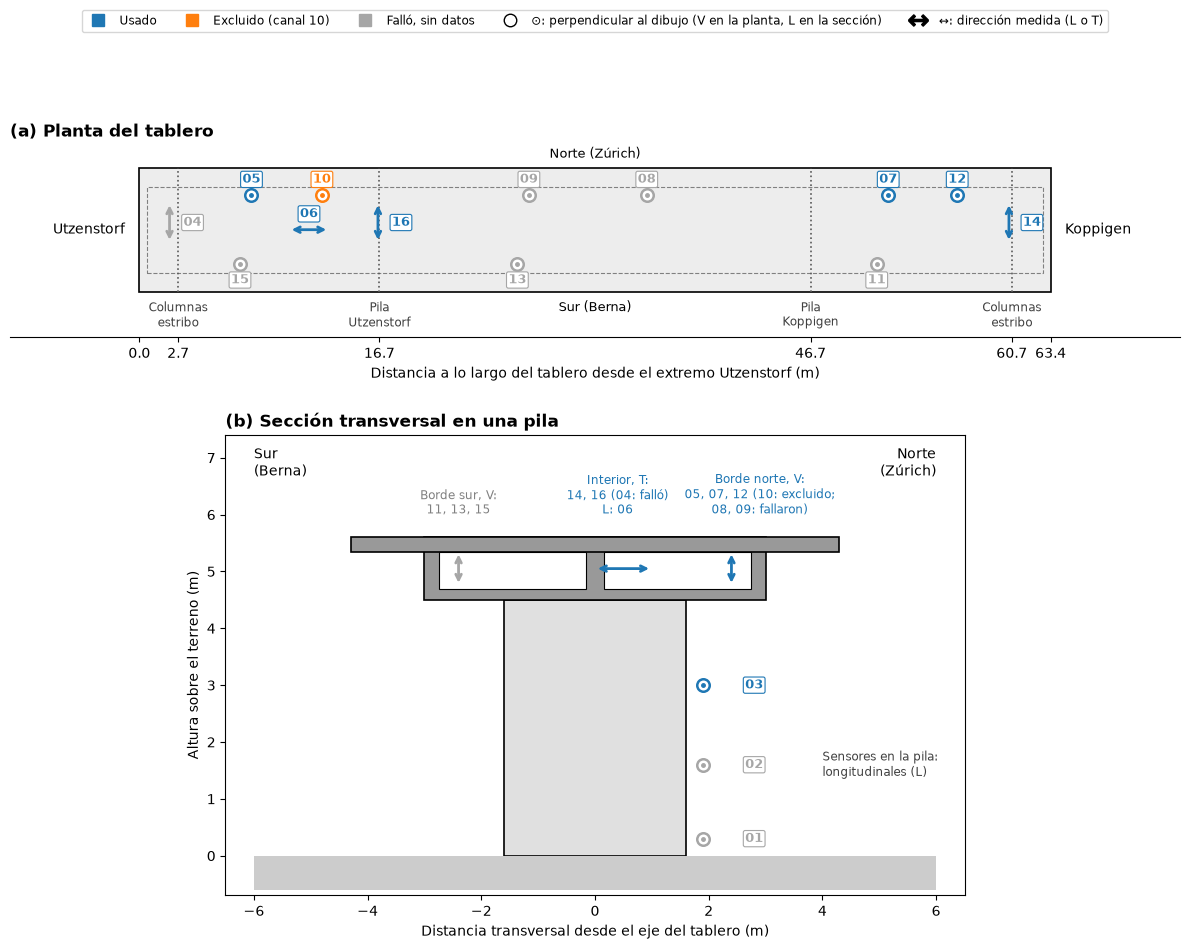

**Figura 1.** Esquema del puente Z24 con los acelerómetros del EMS (posiciones aproximadas, según la Fig. 37 de `Z24-EMS-readme.pdf`; geometría de la Fig. 27 de `C11-Appendices.pdf`). (a) Planta del tablero, sin el esviaje; líneas punteadas: apoyos; línea discontinua: cajón. (b) Sección transversal: sensores 01–03 en la pila (no se indica en cuál de las dos) y posición transversal de los sensores del tablero. En azul, los 7 canales usados en este análisis.

In [3]:
# Approximate sensor positions read from Fig. 37 of Z24-EMS-readme.pdf
# x: distance along the deck from the Utzenstorf end (m); y: transverse distance from the deck axis, north > 0 (m)
X_SUPPORTS = {"Columnas\nestribo": 2.7, "Pila\nUtzenstorf": 16.7, "Pila\nKoppigen": 46.7, "Columnas\nestribo ": 60.7}
DECK_LENGTH, DECK_HALF_WIDTH, BOX_HALF_WIDTH = 63.4, 4.3, 3.0
deck_sensors = {   # channel: (x, y, direction)
    "04": (2.1, 0.5, "T"), "05": (7.8, 2.4, "V"), "06": (11.8, 0.0, "L"), "07": (52.1, 2.4, "V"), "08": (35.3, 2.4, "V"),
    "09": (27.1, 2.4, "V"), "10": (12.7, 2.4, "V"), "11": (51.3, -2.4, "V"), "12": (56.9, 2.4, "V"),
    "13": (26.3, -2.4, "V"), "14": (60.5, 0.5, "T"), "15": (7.0, -2.4, "V"), "16": (16.6, 0.5, "T"),
}
pier_sensors = {"01": 0.3, "02": 1.6, "03": 3.0}   # height above the ground (m), all longitudinal (L)
status_style = {"used": ("C0", "Usado"), "excluded": ("C1", "Excluido (canal 10)"), "failed": ("0.65", "Falló, sin datos")}


def status(ch):
    return "used" if ch in CHANNELS else "excluded" if ch == "10" else "failed"


def draw_sensor(ax, x, y, direction, ch, size=1.4, label_offset=(0, 0.9)):
    color = status_style[status(ch)][0]
    if direction == "V":     # perpendicular to the drawing: circle with a dot
        ax.plot(x, y, "o", ms=9, mfc="white", mec=color, mew=1.8, zorder=5)
        ax.plot(x, y, ".", ms=5, color=color, zorder=6)
    else:                    # in the drawing: double arrow along the measuring direction
        dx, dy = (size, 0) if direction == "L" else (0, size)
        ax.annotate("", xy=(x + dx, y + dy), xytext=(x - dx, y - dy), zorder=5,
                    arrowprops=dict(arrowstyle="<->", color=color, lw=2))
    ax.text(x + label_offset[0], y + label_offset[1], ch, ha="center", va="center", fontsize=9, fontweight="bold",
            color=color, zorder=6, bbox=dict(boxstyle="round,pad=0.15", fc="white", ec=color, lw=0.8))


fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9.5), gridspec_kw={"height_ratios": [1, 1.25]})

# (a) Plan view of the deck
ax1.add_patch(plt.Rectangle((0, -DECK_HALF_WIDTH), DECK_LENGTH, 2 * DECK_HALF_WIDTH, fc="0.93", ec="k", lw=1.2))
ax1.add_patch(plt.Rectangle((0.5, -BOX_HALF_WIDTH), DECK_LENGTH - 1, 2 * BOX_HALF_WIDTH, fc="none", ec="0.5",
                            ls="--", lw=0.8))
for name, x in X_SUPPORTS.items():
    ax1.plot([x, x], [-DECK_HALF_WIDTH, DECK_HALF_WIDTH], color="0.35", ls=":", lw=1.2)
    ax1.text(x, -DECK_HALF_WIDTH - 0.6, name.strip(), ha="center", va="top", fontsize=8.5, color="0.25")
for ch, (x, y, d) in deck_sensors.items():
    off = (1.6, 0) if d == "T" else (0, 1.1) if y >= 0 else (0, -1.1)
    draw_sensor(ax1, x, y, d, ch, label_offset=off)
ax1.text(-1, 0, "Utzenstorf", ha="right", va="center", fontsize=10)
ax1.text(DECK_LENGTH + 1, 0, "Koppigen", ha="left", va="center", fontsize=10)
ax1.text(DECK_LENGTH / 2, DECK_HALF_WIDTH + 0.5, "Norte (Zúrich)", ha="center", va="bottom", fontsize=9)
ax1.text(DECK_LENGTH / 2, -DECK_HALF_WIDTH - 0.6, "Sur (Berna)", ha="center", va="top", fontsize=9)
ax1.set_xlim(-9, DECK_LENGTH + 9)
ax1.set_ylim(-DECK_HALF_WIDTH - 3.2, DECK_HALF_WIDTH + 1.6)
ax1.set_aspect("equal")
ax1.set_xticks([0] + list(X_SUPPORTS.values()) + [DECK_LENGTH])
ax1.set_yticks([])
ax1.set_xlabel("Distancia a lo largo del tablero desde el extremo Utzenstorf (m)")
for side in ("left", "right", "top"):
    ax1.spines[side].set_visible(False)
ax1.set_title("(a) Planta del tablero", loc="left", fontweight="bold")

# (b) Cross section at a pier (south on the left, north on the right, as in Fig. 37)
H_PIER, PIER_HALF_WIDTH, DECK_DEPTH, SLAB = 4.5, 1.6, 1.1, 0.25
ax2.add_patch(plt.Rectangle((-PIER_HALF_WIDTH, 0), 2 * PIER_HALF_WIDTH, H_PIER, fc="0.88", ec="k", lw=1.2))
ax2.add_patch(plt.Rectangle((-BOX_HALF_WIDTH, H_PIER), 2 * BOX_HALF_WIDTH, DECK_DEPTH, fc="0.6", ec="k", lw=1.2))
ax2.add_patch(plt.Rectangle((-DECK_HALF_WIDTH, H_PIER + DECK_DEPTH - SLAB), 2 * DECK_HALF_WIDTH, SLAB, fc="0.6",
                            ec="k", lw=1.2))
for x0 in (-BOX_HALF_WIDTH + 0.25, 0.15):   # the two cells of the box
    ax2.add_patch(plt.Rectangle((x0, H_PIER + 0.2), BOX_HALF_WIDTH - 0.4, DECK_DEPTH - SLAB - 0.2, fc="white",
                                ec="k", lw=0.8))
ax2.fill_between([-6, 6], -0.6, 0, color="0.8", hatch="///", ec="0.5", lw=0)
for ch, h in pier_sensors.items():
    draw_sensor(ax2, PIER_HALF_WIDTH + 0.3, h, "V", ch, label_offset=(0.9, 0))   # L is perpendicular to the section

# Deck sensors seen in the cross section, grouped by transverse position
y_deck = H_PIER + 0.55
groups = [(-2.4, "V", ["11", "13", "15"]), (2.4, "V", ["05", "07", "08", "09", "10", "12"]),
          (0.5, "T", ["04", "14", "16"])]
for y, d, chs in groups:
    color = "C0" if any(status(c) == "used" for c in chs) else "0.65"
    if d == "V":
        ax2.annotate("", xy=(y, y_deck + 0.3), xytext=(y, y_deck - 0.3),
                     arrowprops=dict(arrowstyle="<->", color=color, lw=2))
    else:
        ax2.annotate("", xy=(y + 0.5, y_deck), xytext=(y - 0.5, y_deck),
                     arrowprops=dict(arrowstyle="<->", color=color, lw=2))
ax2.text(-2.4, H_PIER + DECK_DEPTH + 0.35, "Borde sur, V:\n11, 13, 15", ha="center", va="bottom", fontsize=8.5,
         color="0.5")
ax2.text(2.9, H_PIER + DECK_DEPTH + 0.35, "Borde norte, V:\n05, 07, 12 (10: excluido;\n08, 09: fallaron)",
         ha="center", va="bottom", fontsize=8.5, color="C0")
ax2.text(0.4, H_PIER + DECK_DEPTH + 0.35, "Interior, T:\n14, 16 (04: falló)\nL: 06", ha="center", va="bottom",
         fontsize=8.5, color="C0")
ax2.text(-6, H_PIER + 2.7, "Sur\n(Berna)", ha="left", va="top", fontsize=10)
ax2.text(6, H_PIER + 2.7, "Norte\n(Zúrich)", ha="right", va="top", fontsize=10)
ax2.text(PIER_HALF_WIDTH + 2.4, 1.6, "Sensores en la pila:\nlongitudinales (L)", ha="left", va="center", fontsize=8.5,
         color="0.25")
ax2.set_xlim(-6.5, 6.5)
ax2.set_ylim(-0.7, H_PIER + 2.9)
ax2.set_aspect("equal")
ax2.set_xlabel("Distancia transversal desde el eje del tablero (m)")
ax2.set_ylabel("Altura sobre el terreno (m)")
ax2.set_title("(b) Sección transversal en una pila", loc="left", fontweight="bold")

handles = [plt.Line2D([], [], ls="", marker="s", ms=9, color=c, label=l) for c, l in status_style.values()]
handles += [plt.Line2D([], [], ls="", marker="o", ms=9, mfc="white", mec="k", label="⊙: perpendicular al dibujo (V en la planta, L en la sección)"),
            plt.Line2D([], [], ls="", marker="$\\leftrightarrow$", ms=14, color="k", label="↔: dirección medida (L o T)")]
fig.legend(handles=handles, loc="upper center", ncol=5, fontsize=8.5, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.96))

f_num += 1
show_figure(fig, f_num, "Esquema del puente Z24 con los acelerómetros del EMS (posiciones aproximadas, según la Fig. 37 "
            "de `Z24-EMS-readme.pdf`; geometría de la Fig. 27 de `C11-Appendices.pdf`). (a) Planta del tablero, sin el "
            "esviaje; líneas punteadas: apoyos; línea discontinua: cajón. (b) Sección transversal: sensores 01–03 en la "
            "pila (no se indica en cuál de las dos) y posición transversal de los sensores del tablero. En azul, los 7 "
            "canales usados en este análisis.")

---
<a id="sec2"></a>
## 2. Efecto de la temperatura en las frecuencias del puente sano

La temperatura de cada medición se toma de `cache/ems_inventory.csv` (generado en `z24_data_structure.ipynb`): el promedio de la lectura ambiental tomada justo antes de las aceleraciones (PRE).

Se usa la **temperatura del pavimento**: el promedio de `TP1` y `TP2` (secciones 1 y 2 del tablero), en °C. Se elige porque:
- tiene datos en todas las horas del periodo sano;
- es la que más se correlaciona con las frecuencias (las temperaturas del tablero dan resultados parecidos; la del aire, `AT`, algo menos);
- la literatura del Z24 atribuye la subida de las frecuencias con el frío a la rigidización del asfalto.

**Preparación del daño.** Antes del primer descenso de la pila se instaló el sistema para bajarla. Las fechas se acotan con los informes de los ensayos PDT (`.DOC` dentro de `pdt_01-08.zip`) y los apéndices del informe:

**Tabla 2.** Fechas de la preparación del daño.

| Fecha | Qué pasó | Fuente |
|---|---|---|
| 04–05.08.1998 | Referencia 1 (escenario 01): puente sano, sin el sistema | `168'349_701A.DOC` |
| 05–10.08.1998 | Instalación del sistema en la pila Koppigen: se cortan tres tramos de la pila y se reemplazan por piezas de acero con gatos hidráulicos | Apéndice D de `C11-Appendices.pdf` (sin fechas) |
| 09–10.08.1998 | Referencia 2 (escenario 02): sistema instalado, pila sin bajar | `168'349_702A.DOC` |
| 11.08.1998, 13:15 | Primer descenso de la pila (−20 mm): primer daño | Tabla 8 del Apéndice F de `C11-Appendices.pdf` |

La instalación no es un daño, pero cambia la pila. Por eso las mediciones desde el 05.08.1998 hasta el primer descenso se separan del resto del periodo sano (Tabla 3). La Figura 2 las muestra en otro color y la Figura 3 usa solo las mediciones anteriores al 05.08.1998.

**Tabla 3.** Periodos del monitoreo. La preparación del daño va del 05.08.1998 al primer descenso de la pila (11.08.1998, 13:15).

Periodo,Desde,Hasta,Mediciones
Sano,10.11.1997 14:00,04.08.1998 23:00,4821
Preparación del daño,05.08.1998 00:00,11.08.1998 13:00,158
Con daño,11.08.1998 14:00,10.09.1998 13:00,674


Healthy measurements with temperature: 4979 of 4979 | T from -6.7 to 40.4 °C


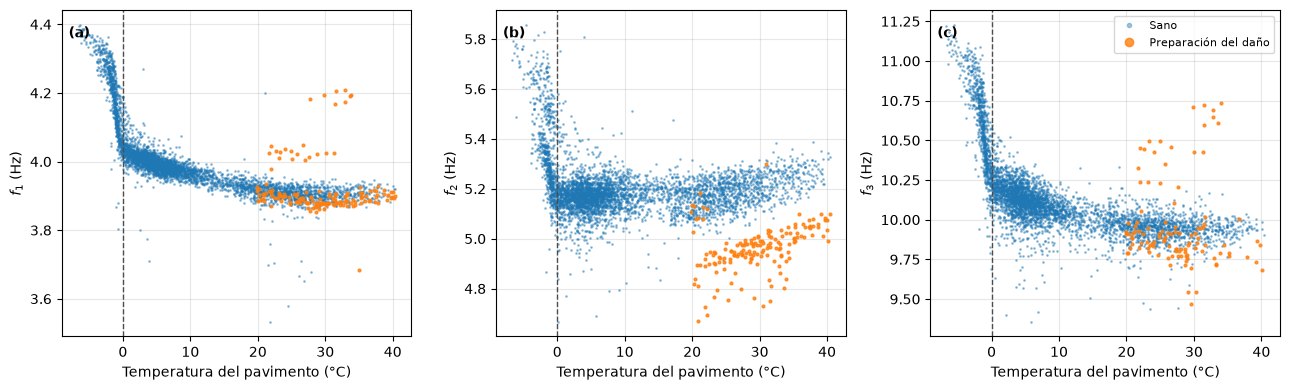

**Figura 2.** Frecuencia natural frente a la temperatura del pavimento en las mediciones anteriores al primer daño: (a) modo 1, (b) modo 2 y (c) modo 3. Azul: puente sano (antes del 05.08.1998); naranja: preparación del daño (05.08.1998 al 11.08.1998, 13:15). La línea discontinua marca 0 °C.

In [4]:
env = pd.read_csv(CACHE_DIR / "ems_inventory.csv", usecols=["code", "TP1", "TP2"])
env[["TP1", "TP2"]] = env[["TP1", "TP2"]].where(env[["TP1", "TP2"]].abs() < SENTINEL_ABS)   # error codes -> NaN
env["T"] = env[["TP1", "TP2"]].mean(axis=1)            # pavement temperature (°C)
modal = modal.merge(env[["code", "T"]], on="code", how="left")

modal["period"] = np.select([modal["start"] < PREP_START, modal["start"] < DAMAGE_START],
                            ["Sano", "Preparación del daño"], "Con daño")

periods = modal.groupby("period", sort=False).agg(Desde=("start", "min"), Hasta=("start", "max"),
                                                  Mediciones=("code", "size")).reset_index()
periods = periods.rename(columns={"period": "Periodo"})
periods[["Desde", "Hasta"]] = periods[["Desde", "Hasta"]].apply(lambda s: s.dt.strftime("%d.%m.%Y %H:%M"))
t_num += 2   # Table 2 is the markdown table of preparation dates above
show_table(periods, t_num, "Periodos del monitoreo. La preparación del daño va del 05.08.1998 al primer descenso de "
           "la pila (11.08.1998, 13:15).", hide_index=True)

healthy = modal[modal["healthy"]]
print(f"Healthy measurements with temperature: {healthy['T'].notna().sum()} of {len(healthy)} | "
      f"T from {healthy['T'].min():.1f} to {healthy['T'].max():.1f} °C")

fig, axes = plt.subplots(1, len(MODE_BANDS), figsize=(13, 4))
for i, (ax, m) in enumerate(zip(axes, MODE_BANDS)):
    for period, color in [("Sano", "C0"), ("Preparación del daño", "C1")]:
        sel = healthy[healthy["period"] == period]
        ax.plot(sel["T"], sel[f"f{m}"], ".", ms=2 if period == "Sano" else 4, alpha=0.4 if period == "Sano" else 0.8,
                color=color, label=period)
    ax.axvline(0, color="0.3", ls="--", lw=1)
    ax.set_xlabel("Temperatura del pavimento (°C)")
    ax.set_ylabel(f"$f_{m}$ (Hz)")
    ax.grid(alpha=0.3)
    ax.text(0.02, 0.95, f"({chr(97 + i)})", transform=ax.transAxes, va="top", fontweight="bold")
axes[-1].legend(markerscale=3, fontsize=8, loc="upper right")
fig.tight_layout()

f_num += 1
show_figure(fig, f_num, "Frecuencia natural frente a la temperatura del pavimento en las mediciones anteriores al "
            "primer daño: (a) modo 1, (b) modo 2 y (c) modo 3. Azul: puente sano (antes del 05.08.1998); naranja: "
            "preparación del daño (05.08.1998 al 11.08.1998, 13:15). La línea discontinua marca 0 °C.")

- **Sobre 0 °C:** las frecuencias bajan poco a poco al subir la temperatura (por ejemplo, el modo 1 pasa de unos 4.05 Hz cerca de 0 °C a unos 3.90 Hz sobre 25 °C).
- **Bajo 0 °C:** las frecuencias suben con fuerza (el modo 1 llega a 4.4 Hz, el modo 2 a 5.8 Hz y el modo 3 a 11.1 Hz). El cambio de pendiente en 0 °C es el comportamiento bilineal que reporta la literatura del Z24 (asfalto y suelo congelados).
- **Modo 2:** sobre 0 °C casi no depende de la temperatura. Las mediciones de la preparación del daño (naranja) quedan debajo de la nube del puente sano (4.7 a 5.05 Hz): la instalación del sistema en la pila ya baja la frecuencia del modo 2.
- **Modos 1 y 3 en la preparación:** casi todas las mediciones caen dentro de la nube del puente sano, salvo unas horas con valores anormalmente altos (hasta 4.2 Hz y 10.7 Hz), todas del 06 y 07.08.1998.

La Figura 3 repite la Figura 2 solo con las mediciones del puente sano, anteriores al 05.08.1998.

Measurements before 1998-08-05: 4821 | T from -6.7 to 40.4 °C


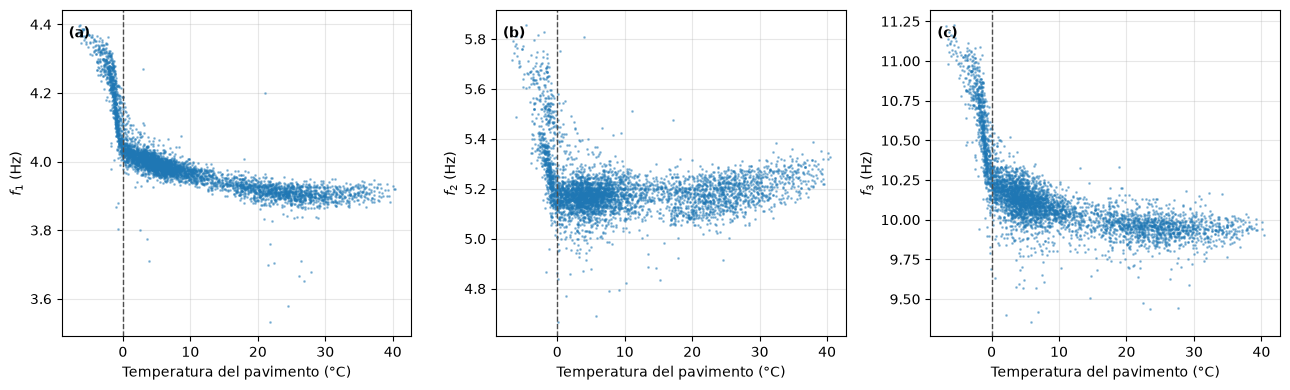

**Figura 3.** Frecuencia natural frente a la temperatura del pavimento en las mediciones del puente sano anteriores al 05.08.1998: (a) modo 1, (b) modo 2 y (c) modo 3. La línea discontinua marca 0 °C.

In [5]:
sano = modal[modal["period"] == "Sano"]
print(f"Measurements before {PREP_START.date()}: {len(sano)} | T from {sano['T'].min():.1f} to {sano['T'].max():.1f} °C")

fig, axes = plt.subplots(1, len(MODE_BANDS), figsize=(13, 4))
for i, (ax, m) in enumerate(zip(axes, MODE_BANDS)):
    ax.plot(sano["T"], sano[f"f{m}"], ".", ms=2, alpha=0.4, color="C0")
    ax.axvline(0, color="0.3", ls="--", lw=1)
    ax.set_xlabel("Temperatura del pavimento (°C)")
    ax.set_ylabel(f"$f_{m}$ (Hz)")
    ax.grid(alpha=0.3)
    ax.text(0.02, 0.95, f"({chr(97 + i)})", transform=ax.transAxes, va="top", fontweight="bold")
fig.tight_layout()

f_num += 1
show_figure(fig, f_num, "Frecuencia natural frente a la temperatura del pavimento en las mediciones del puente sano "
            "anteriores al 05.08.1998: (a) modo 1, (b) modo 2 y (c) modo 3. La línea discontinua marca 0 °C.")

---
<a id="sec3"></a>
## 3. Análisis bivariado de las frecuencias naturales

Prueba de análisis bivariado entre cada par de frecuencias: $(f_1, f_2)$, $(f_1, f_3)$ y $(f_2, f_3)$. Se usan solo las mediciones del puente sano anteriores al 05.08.1998 (sin la preparación del daño), y en cada par solo las mediciones en que se identificaron los dos modos.

La dependencia entre dos frecuencias se mide con dos coeficientes de correlación:

$$
r = \frac{\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^{n} (x_i - \bar{x})^2}\,\sqrt{\sum_{i=1}^{n} (y_i - \bar{y})^2}}
\tag{1}
$$

donde $x_i$ e $y_i$ son las dos frecuencias en la medición $i$, $\bar{x}$ e $\bar{y}$ sus medias y $n$ el número de mediciones. Es el coeficiente de **Pearson**: mide qué tan bien se alinean los puntos en una recta (−1 a 1).

El coeficiente de **Spearman** $\rho_s$ es la Ec. (1) aplicada a los rangos de $x_i$ e $y_i$ (su posición al ordenarlos) en vez de a los valores. Mide si una frecuencia sube cuando la otra sube, aunque la relación no sea una recta, y le afectan menos los valores atípicos.

Como la temperatura cambia las tres frecuencias a la vez y lo hace de forma distinta bajo y sobre 0 °C (sección 2), los coeficientes se calculan con todas las mediciones y por separado para temperaturas del pavimento bajo 0 °C y desde 0 °C.

In [6]:
PAIRS = [(1, 2), (1, 3), (2, 3)]
sano = modal[modal["period"] == "Sano"]

rows = []
for a, b in PAIRS:
    for label, sel in [("Todas", sano), ("T < 0 °C", sano[sano["T"] < 0]), ("T ≥ 0 °C", sano[sano["T"] >= 0])]:
        xy = sel[[f"f{a}", f"f{b}"]].dropna()
        rows.append({"Par": f"f{a} – f{b}", "Mediciones": label, "n": len(xy),
                     "Pearson r": xy.corr(method="pearson").iloc[0, 1],
                     "Spearman ρs": xy.corr(method="spearman").iloc[0, 1]})
corr = pd.DataFrame(rows)

t_num += 1
show_table(corr, t_num, "Coeficientes de correlación entre cada par de frecuencias naturales (puente sano, antes del "
           "05.08.1998), con todas las mediciones y separando por la temperatura del pavimento.", precision=2,
           hide_index=True)

**Tabla 4.** Coeficientes de correlación entre cada par de frecuencias naturales (puente sano, antes del 05.08.1998), con todas las mediciones y separando por la temperatura del pavimento.

Par,Mediciones,n,Pearson r,Spearman ρs
f1 – f2,Todas,4680,0.65,0.27
f1 – f2,T < 0 °C,746,0.80,0.85
f1 – f2,T ≥ 0 °C,3934,0.06,-0.02
f1 – f3,Todas,4659,0.91,0.83
f1 – f3,T < 0 °C,772,0.88,0.91
f1 – f3,T ≥ 0 °C,3887,0.66,0.73
f2 – f3,Todas,4604,0.66,0.28
f2 – f3,T < 0 °C,728,0.78,0.82
f2 – f3,T ≥ 0 °C,3876,0.10,0.00


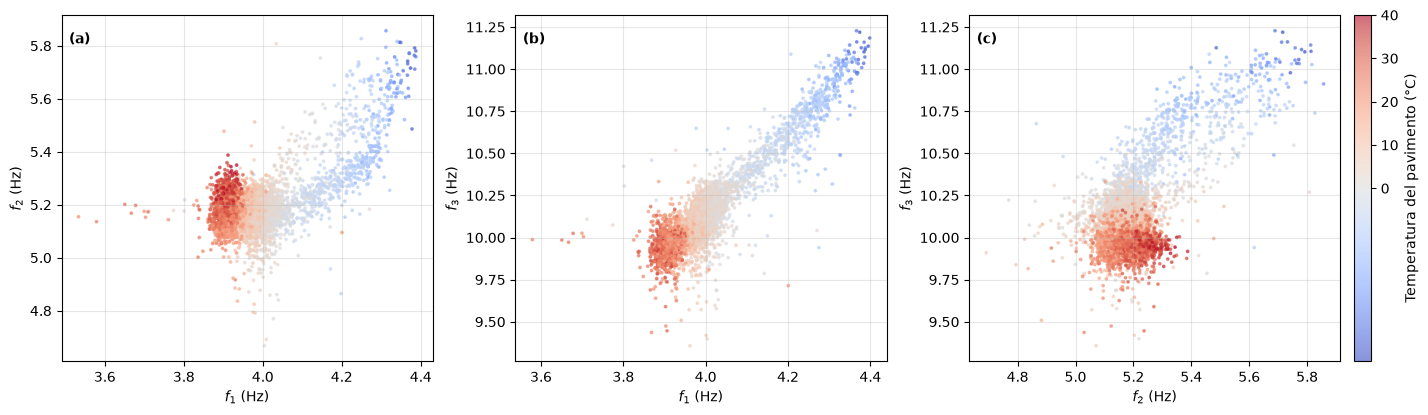

**Figura 4.** Diagramas de dispersión entre cada par de frecuencias naturales (puente sano, antes del 05.08.1998): (a) $f_1$–$f_2$, (b) $f_1$–$f_3$ y (c) $f_2$–$f_3$. El color indica la temperatura del pavimento (blanco en 0 °C; azul bajo 0 °C, rojo sobre 0 °C).

In [7]:
fig, axes = plt.subplots(1, len(PAIRS), figsize=(14, 4.2))
for i, (ax, (a, b)) in enumerate(zip(axes, PAIRS)):
    xy = sano[[f"f{a}", f"f{b}", "T"]].dropna()
    sc = ax.scatter(xy[f"f{a}"], xy[f"f{b}"], c=xy["T"], s=3, alpha=0.6, cmap="coolwarm",
                    norm=TwoSlopeNorm(vmin=-7, vcenter=0, vmax=40))   # white at 0 °C
    ax.set_xlabel(f"$f_{a}$ (Hz)")
    ax.set_ylabel(f"$f_{b}$ (Hz)")
    ax.grid(alpha=0.3)
    ax.text(0.02, 0.95, f"({chr(97 + i)})", transform=ax.transAxes, va="top", fontweight="bold")
fig.tight_layout()
fig.colorbar(sc, ax=axes, label="Temperatura del pavimento (°C)", fraction=0.02, pad=0.01)

f_num += 1
show_figure(fig, f_num, "Diagramas de dispersión entre cada par de frecuencias naturales (puente sano, antes del "
            "05.08.1998): (a) $f_1$–$f_2$, (b) $f_1$–$f_3$ y (c) $f_2$–$f_3$. El color indica la temperatura del "
            "pavimento (blanco en 0 °C; azul bajo 0 °C, rojo sobre 0 °C).")

- **Con todas las mediciones** las tres frecuencias están correlacionadas de forma positiva, sobre todo $f_1$ y $f_3$ ($r = 0.91$). Esa correlación la produce casi toda la helada: bajo 0 °C las tres suben juntas y los puntos forman una franja diagonal (azul en la Figura 4).
- **Bajo 0 °C** los tres pares están muy correlacionados ($ho_s$ entre 0.82 y 0.91).
- **Desde 0 °C** solo $f_1$ y $f_3$ siguen correlacionadas ($ho_s = 0.73$): las dos bajan al subir la temperatura. $f_2$ casi no se relaciona con $f_1$ ni con $f_3$ ($ho_s pprox 0$), porque sobre 0 °C el modo 2 casi no depende de la temperatura (sección 2).
- **Para modelar la distribución conjunta:** la dependencia entre las frecuencias no es la misma en todo el rango, cambia con la temperatura. Una distribución conjunta con una sola correlación (por ejemplo, normal bivariada) no la representaría bien; conviene separar por régimen de temperatura o modelar las frecuencias condicionadas a la temperatura.

---
<a id="sec4"></a>
## 4. Normalización de las frecuencias por temperatura

**Objetivo:** llevar todas las mediciones a una misma temperatura de referencia, para comparar el puente sano y el dañado sin el efecto del frío o del calor.

**Pasos:**
1. Ajustar, para cada modo, un modelo de la frecuencia en función de la temperatura con el puente sano (antes del 05.08.1998).
2. Revisar qué tan bien ajusta (residuos).
3. Restar el efecto de la temperatura de cada medición y llevarla a $T_{ref} = 10$ °C.
4. Comparar los periodos sano, preparación y con daño.

### 4.1 Modelo bilineal

La Figura 2 muestra dos rectas unidas en 0 °C: una suave sobre 0 °C y otra muy inclinada bajo 0 °C. El modelo de cada modo $m$ es:

$$
\hat f_m(T) = a_m + b_m\,T + c_m \min(T, 0)
\tag{2}
$$

- $T$: temperatura del pavimento (°C).
- $a_m$: frecuencia en 0 °C, donde se unen las dos rectas (Hz).
- $b_m$: pendiente sobre 0 °C (Hz/°C).
- $b_m + c_m$: pendiente bajo 0 °C (Hz/°C). El término $\min(T, 0)$ vale $T$ bajo 0 °C y 0 sobre 0 °C, así que $c_m$ solo actúa con helada.

Es una regresión lineal con dos variables, $T$ y $\min(T, 0)$, y se ajusta por mínimos cuadrados.

La calidad del ajuste se mide con el residuo $e = f_m - \hat f_m(T)$, la parte de la frecuencia que el modelo no explica:
- $R^2 = 1 - \mathrm{Var}(e)/\mathrm{Var}(f_m)$: fracción de la variación de la frecuencia que explica la temperatura (0 a 1).
- RMSE $= \sqrt{\overline{e^2}}$: error típico del modelo, en Hz.

**Tabla 5.** Coeficientes del modelo bilineal (Ec. 2) de cada modo, ajustado con el puente sano (antes del 05.08.1998), y calidad del ajuste.

Modo,n,a (Hz),b (Hz/°C),b + c (Hz/°C),R²,RMSE (Hz),RMSE T < 0 °C (Hz),RMSE T ≥ 0 °C (Hz)
1,4768,4.0263,-0.0047,-0.0886,0.8622,0.0384,0.0682,0.0289
2,4731,5.1658,0.0010,-0.1138,0.4868,0.0813,0.1318,0.0677
3,4688,10.1834,-0.0096,-0.2208,0.7840,0.1173,0.1827,0.0994


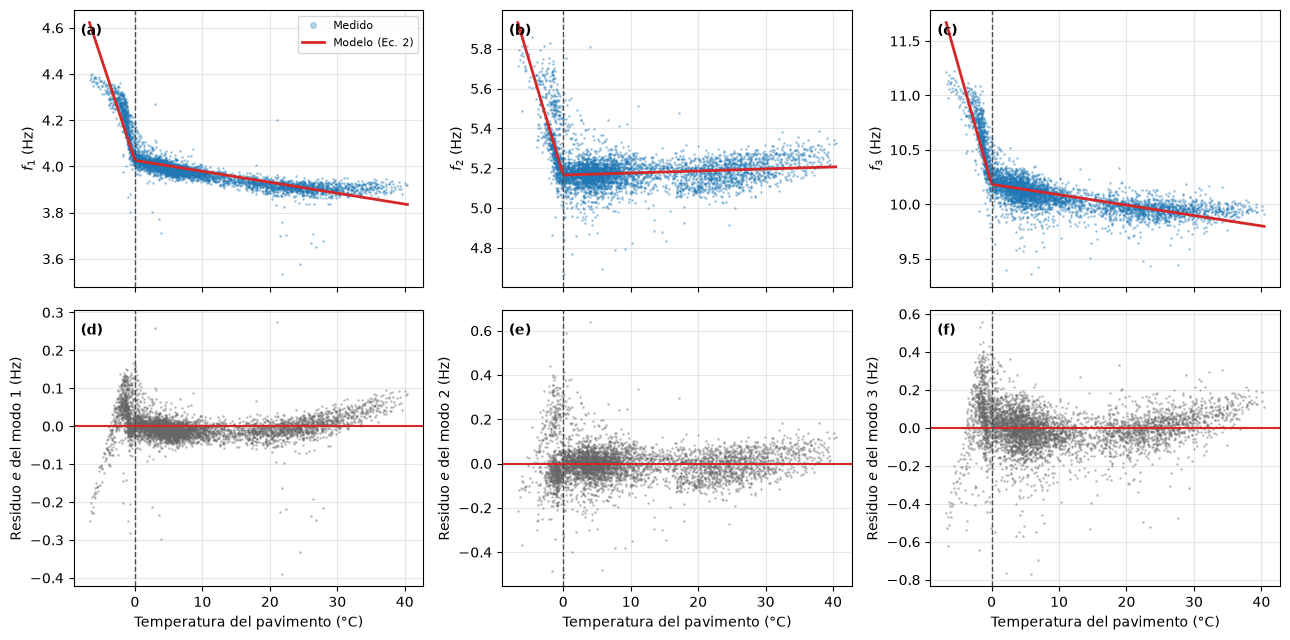

**Figura 5.** Modelo bilineal de cada modo (puente sano, antes del 05.08.1998). Arriba, (a)–(c): frecuencia medida y modelo de los modos 1, 2 y 3. Abajo, (d)–(f): residuo (medido menos modelo). La línea discontinua marca 0 °C.

In [8]:
T_REF = 10.0   # reference temperature for the normalization (°C)


def bilinear_terms(T):
    # Regressors of Eq. 2: intercept, T and min(T, 0)
    T = np.atleast_1d(np.asarray(T, float))
    return np.column_stack([np.ones_like(T), T, np.minimum(T, 0)])


coefs, rows = {}, []
for m in MODE_BANDS:
    d = sano[["T", f"f{m}"]].dropna()
    T, fm = d["T"].to_numpy(), d[f"f{m}"].to_numpy()
    coefs[m], *_ = np.linalg.lstsq(bilinear_terms(T), fm, rcond=None)   # least squares fit of Eq. 2
    e = fm - bilinear_terms(T) @ coefs[m]
    a, b, c = coefs[m]
    rows.append({"Modo": m, "n": len(fm), "a (Hz)": a, "b (Hz/°C)": b, "b + c (Hz/°C)": b + c,
                 "R²": 1 - e.var() / fm.var(), "RMSE (Hz)": np.sqrt(np.mean(e ** 2)),
                 "RMSE T < 0 °C (Hz)": np.sqrt(np.mean(e[T < 0] ** 2)),
                 "RMSE T ≥ 0 °C (Hz)": np.sqrt(np.mean(e[T >= 0] ** 2))})

t_num += 1
show_table(pd.DataFrame(rows), t_num, "Coeficientes del modelo bilineal (Ec. 2) de cada modo, ajustado con el puente "
           "sano (antes del 05.08.1998), y calidad del ajuste.", precision=4, hide_index=True)

T_grid = np.linspace(sano["T"].min(), sano["T"].max(), 200)
fig, axes = plt.subplots(2, len(MODE_BANDS), figsize=(13, 6.5), sharex=True)
for i, m in enumerate(MODE_BANDS):
    d = sano[["T", f"f{m}"]].dropna()
    e = d[f"f{m}"] - bilinear_terms(d["T"]) @ coefs[m]
    ax = axes[0, i]
    ax.plot(d["T"], d[f"f{m}"], ".", ms=2, alpha=0.3, color="C0", label="Medido")
    ax.plot(T_grid, bilinear_terms(T_grid) @ coefs[m], color="C3", lw=2, label="Modelo (Ec. 2)")
    ax.set_ylabel(f"$f_{m}$ (Hz)")
    ax = axes[1, i]
    ax.plot(d["T"], e, ".", ms=2, alpha=0.3, color="0.4")
    ax.axhline(0, color="C3", lw=1.5)
    ax.set_ylabel(f"Residuo $e$ del modo {m} (Hz)")
    ax.set_xlabel("Temperatura del pavimento (°C)")
    for j, ax in enumerate(axes[:, i]):
        ax.axvline(0, color="0.3", ls="--", lw=1)
        ax.grid(alpha=0.3)
        ax.text(0.02, 0.95, f"({chr(97 + i + 3 * j)})", transform=ax.transAxes, va="top", fontweight="bold")
axes[0, 0].legend(markerscale=4, fontsize=8, loc="upper right")
fig.tight_layout()

f_num += 1
show_figure(fig, f_num, "Modelo bilineal de cada modo (puente sano, antes del 05.08.1998). Arriba, (a)–(c): frecuencia "
            "medida y modelo de los modos 1, 2 y 3. Abajo, (d)–(f): residuo (medido menos modelo). La línea discontinua "
            "marca 0 °C.")

- **Sobre 0 °C** el modelo ajusta bien: el RMSE es de 0.03, 0.07 y 0.10 Hz en los modos 1, 2 y 3.
- **Bajo 0 °C** el error es el doble. Hay dos fallas que se ven en los residuos (Figura 5d–f):
  - cerca de 0 °C hay residuos positivos: el puente sigue congelado aunque la temperatura del pavimento ya subió (inercia térmica del suelo y del asfalto);
  - bajo −4 °C la recta predice frecuencias más altas que las medidas: la rigidez deja de crecer al seguir bajando la temperatura.
- **Modo 2:** sobre 0 °C la pendiente es casi cero; por eso su $R^2$ es bajo (0.49): la temperatura explica poco de su variación.

### 4.2 Frecuencias normalizadas

A cada medición se le quita lo que predice el modelo a su temperatura y se le suma lo que predice a $T_{ref}$:

$$
f_m^{norm} = f_m - \hat f_m(T) + \hat f_m(T_{ref})
\tag{3}
$$

- $f_m$: frecuencia medida del modo $m$; $T$: temperatura del pavimento en esa medición.
- $f_m^{norm}$: la frecuencia que se habría medido a $T_{ref} = 10$ °C.

En palabras: $f_m^{norm}$ es el residuo $e$ más un valor fijo, $\hat f_m(T_{ref})$. El modelo se ajusta solo con el puente sano y después se aplica a todas las mediciones, también a las de la preparación y del daño.

**Ajuste de distribuciones.** A las frecuencias normalizadas del puente sano se les ajustan dos distribuciones por máxima verosimilitud, para ver cuál las describe mejor:

- **Normal**, con media $\mu$ y desviación estándar $\sigma$:

$$
p(x) = \frac{1}{\sigma\sqrt{2\pi}} \exp\!\left[-\frac{1}{2}\left(\frac{x-\mu}{\sigma}\right)^2\right]
\tag{4}
$$

- **t de Student**, con centro $\mu_t$, escala $s$ y grados de libertad $\nu$:

$$
p(x) = \frac{\Gamma\!\left(\frac{\nu+1}{2}\right)}{\Gamma\!\left(\frac{\nu}{2}\right) s\sqrt{\nu\pi}} \left[1 + \frac{1}{\nu}\left(\frac{x-\mu_t}{s}\right)^2\right]^{-\frac{\nu+1}{2}}
\tag{5}
$$

  donde $\Gamma$ es la función gamma. Tiene la misma forma de campana que la normal, pero con colas más pesadas: da más probabilidad a valores lejos del centro. Cuanto menor es $\nu$, más pesadas son las colas; con $\nu \to \infty$ se vuelve una normal.

Se comparan con dos criterios:
- **AIC** (*Akaike Information Criterion*): $\mathrm{AIC} = 2k - 2\ln L$, donde $k$ es el número de parámetros (2 en la normal, 3 en la t) y $\ln L$ el logaritmo de la verosimilitud (qué tan probables son los datos con la distribución ajustada). Menor AIC = mejor ajuste; penaliza el parámetro extra de la t.
- **Estadístico de Kolmogorov-Smirnov** $D$: la mayor diferencia entre la distribución acumulada de los datos y la ajustada. Menor $D$ = mejor ajuste.

**Tabla 6.** Frecuencias medidas (f) y normalizadas a 10 °C (f norm, Ec. 3) en cada periodo.

Modo,Periodo,Media f (Hz),Desv. est. f (Hz),Media f norm (Hz),Desv. est. f norm (Hz)
1,Sano,4.004,0.103,3.979,0.038
1,Preparación del daño,3.919,0.079,4.011,0.081
1,Con daño,3.855,0.046,3.917,0.051
2,Sano,5.203,0.113,5.176,0.081
2,Preparación del daño,4.962,0.094,4.942,0.092
2,Con daño,4.798,0.123,4.783,0.119
3,Sano,10.148,0.252,10.088,0.117
3,Preparación del daño,9.962,0.275,10.129,0.277
3,Con daño,9.749,0.123,9.874,0.118


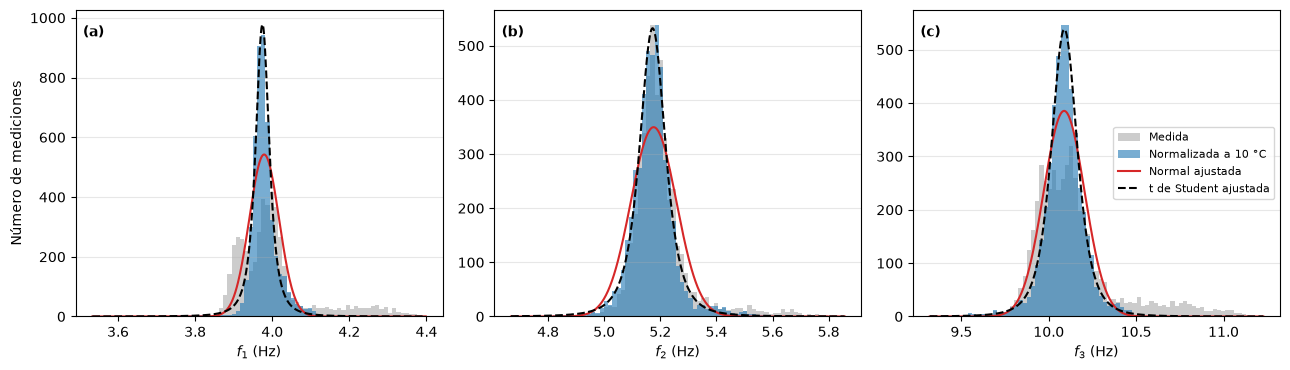

**Figura 6.** Histograma de las frecuencias del puente sano (antes del 05.08.1998), medidas y normalizadas a 10 °C, con la normal (Ec. 4) y la t de Student (Ec. 5) ajustadas a las normalizadas: (a) modo 1, (b) modo 2 y (c) modo 3.

**Tabla 7.** Normal y t de Student ajustadas a las frecuencias normalizadas a 10 °C del puente sano. μ, σ: parámetros de la normal; ν, μt, s: grados de libertad, centro y escala de la t. Menor AIC y menor D = mejor ajuste.

Modo,n,μ (Hz),σ (Hz),ν,μt (Hz),s (Hz),AIC normal,AIC t,D normal,D t,Mejor (AIC)
1,4768,3.9790,0.0384,2.1637,3.9745,0.0190,-17548.6219,-19489.0549,0.1246,0.0447,t de Student
2,4731,5.1760,0.0813,2.8182,5.1723,0.0489,-10319.8565,-11540.5873,0.0925,0.0151,t de Student
3,4688,10.0878,0.1173,3.2375,10.0890,0.0778,-6784.4552,-7559.9855,0.0692,0.0110,t de Student


In [9]:
for m in MODE_BANDS:
    T = modal["T"].to_numpy()
    modal[f"fn{m}"] = modal[f"f{m}"] - bilinear_terms(T) @ coefs[m] + (bilinear_terms(T_REF) @ coefs[m])[0]

rows = []
for period in ["Sano", "Preparación del daño", "Con daño"]:
    sel = modal[modal["period"] == period]
    for m in MODE_BANDS:
        rows.append({"Modo": m, "Periodo": period,
                     "Media f (Hz)": sel[f"f{m}"].mean(), "Desv. est. f (Hz)": sel[f"f{m}"].std(),
                     "Media f norm (Hz)": sel[f"fn{m}"].mean(), "Desv. est. f norm (Hz)": sel[f"fn{m}"].std()})
norm_summary = pd.DataFrame(rows).sort_values("Modo", kind="stable")

t_num += 1
show_table(norm_summary, t_num, f"Frecuencias medidas (f) y normalizadas a {T_REF:.0f} °C (f norm, Ec. 3) en cada "
           "periodo.", precision=3, hide_index=True)

def fit_normal_t(x):
    # Maximum likelihood fit of a normal (Eq. 4) and a Student t (Eq. 5), compared with AIC and the KS statistic
    x = np.asarray(x, float)
    mu, sd = stats.norm.fit(x)
    nu, loc, scale = stats.t.fit(x, 5, loc=np.median(x), scale=sd)   # initial guess: the default start can stall at nu -> inf
    aic_n = 2 * 2 - 2 * stats.norm.logpdf(x, mu, sd).sum()
    aic_t = 2 * 3 - 2 * stats.t.logpdf(x, nu, loc, scale).sum()
    return {"n": len(x), "μ (Hz)": mu, "σ (Hz)": sd, "ν": nu, "μt (Hz)": loc, "s (Hz)": scale,
            "AIC normal": aic_n, "AIC t": aic_t,
            "D normal": stats.kstest(x, lambda v: stats.norm.cdf(v, mu, sd)).statistic,
            "D t": stats.kstest(x, lambda v: stats.t.cdf(v, nu, loc, scale)).statistic,
            "Mejor (AIC)": "t de Student" if aic_t < aic_n else "Normal"}


def plot_fit_hist(healthy, norm_col, caption):
    # Histograms of the measured and normalized frequencies with the fitted normal and t densities
    rows = []
    fig, axes = plt.subplots(1, len(MODE_BANDS), figsize=(13, 3.8))
    for i, (ax, m) in enumerate(zip(axes, MODE_BANDS)):
        raw, norm = healthy[f"f{m}"].dropna(), healthy[norm_col.format(m=m)].dropna()
        fit = fit_normal_t(norm)
        rows.append({"Modo": m, **fit})
        bins = np.linspace(min(raw.min(), norm.min()), max(raw.max(), norm.max()), 80)
        width = bins[1] - bins[0]
        x = np.linspace(bins[0], bins[-1], 500)
        ax.hist(raw, bins=bins, color="0.8", label="Medida")
        ax.hist(norm, bins=bins, color="C0", alpha=0.6, label=f"Normalizada a {T_REF:.0f} °C")
        ax.plot(x, len(norm) * width * stats.norm.pdf(x, fit["μ (Hz)"], fit["σ (Hz)"]), color="C3", lw=1.5,
                label="Normal ajustada")
        ax.plot(x, len(norm) * width * stats.t.pdf(x, fit["ν"], fit["μt (Hz)"], fit["s (Hz)"]), color="k", lw=1.5,
                ls="--", label="t de Student ajustada")
        ax.set_xlabel(f"$f_{m}$ (Hz)")
        ax.grid(axis="y", alpha=0.3)
        ax.text(0.02, 0.95, f"({chr(97 + i)})", transform=ax.transAxes, va="top", fontweight="bold")
    axes[0].set_ylabel("Número de mediciones")
    axes[-1].legend(fontsize=8, loc="center right")
    fig.tight_layout()
    global f_num
    f_num += 1
    show_figure(fig, f_num, caption)
    return pd.DataFrame(rows)


sano = modal[modal["period"] == "Sano"]
fits = plot_fit_hist(sano, "fn{m}", "Histograma de las frecuencias del puente sano (antes del 05.08.1998), medidas y "
                     f"normalizadas a {T_REF:.0f} °C, con la normal (Ec. 4) y la t de Student (Ec. 5) ajustadas a las "
                     "normalizadas: (a) modo 1, (b) modo 2 y (c) modo 3.")

t_num += 1
show_table(fits, t_num, f"Normal y t de Student ajustadas a las frecuencias normalizadas a {T_REF:.0f} °C del puente sano. "
           "μ, σ: parámetros de la normal; ν, μt, s: grados de libertad, centro y escala de la t. Menor AIC y menor D = "
           "mejor ajuste.", precision=4, hide_index=True)

- La normalización reduce la desviación estándar del puente sano: de 0.103 a 0.038 Hz en el modo 1, de 0.113 a 0.081 Hz en el modo 2 y de 0.252 a 0.117 Hz en el modo 3 (Tabla 6).
- Las colas de frecuencias altas de la helada desaparecen casi del todo (Figura 6): las distribuciones quedan estrechas y con un solo pico.
- **Con daño**, la frecuencia normalizada media baja respecto al puente sano: −1.6 % en el modo 1, −7.6 % en el modo 2 y −2.1 % en el modo 3.
- **Normal o t de Student** (Figura 6 y Tabla 7): en los tres modos ajusta mejor la t, con menor AIC y un $D$ de 3 a 6 veces menor (por ejemplo, 0.015 frente a 0.092 en el modo 2). La normal se queda corta en el pico y es demasiado ancha en los costados; la t sigue el pico angosto y las colas.
- Los grados de libertad son bajos ($\nu$ = 2.2, 2.8 y 3.2): las colas son mucho más pesadas que las de una normal. Si se usara una normal, se subestimaría la probabilidad de valores extremos en el puente sano, y una franja de ± 2σ marcaría como anómalas más mediciones sanas de lo esperado.

### 4.3 Comparación del puente sano y el dañado

La Figura 7 muestra las frecuencias normalizadas a lo largo del monitoreo. La franja gris va de $\mu - 2\sigma$ a $\mu + 2\sigma$, donde $\mu$ y $\sigma$ son la media y la desviación estándar de las frecuencias normalizadas del puente sano. Es el rango donde cae cerca del 95 % de las mediciones sanas si se distribuyen de forma normal. El valor de cada límite se indica a la derecha de cada panel.

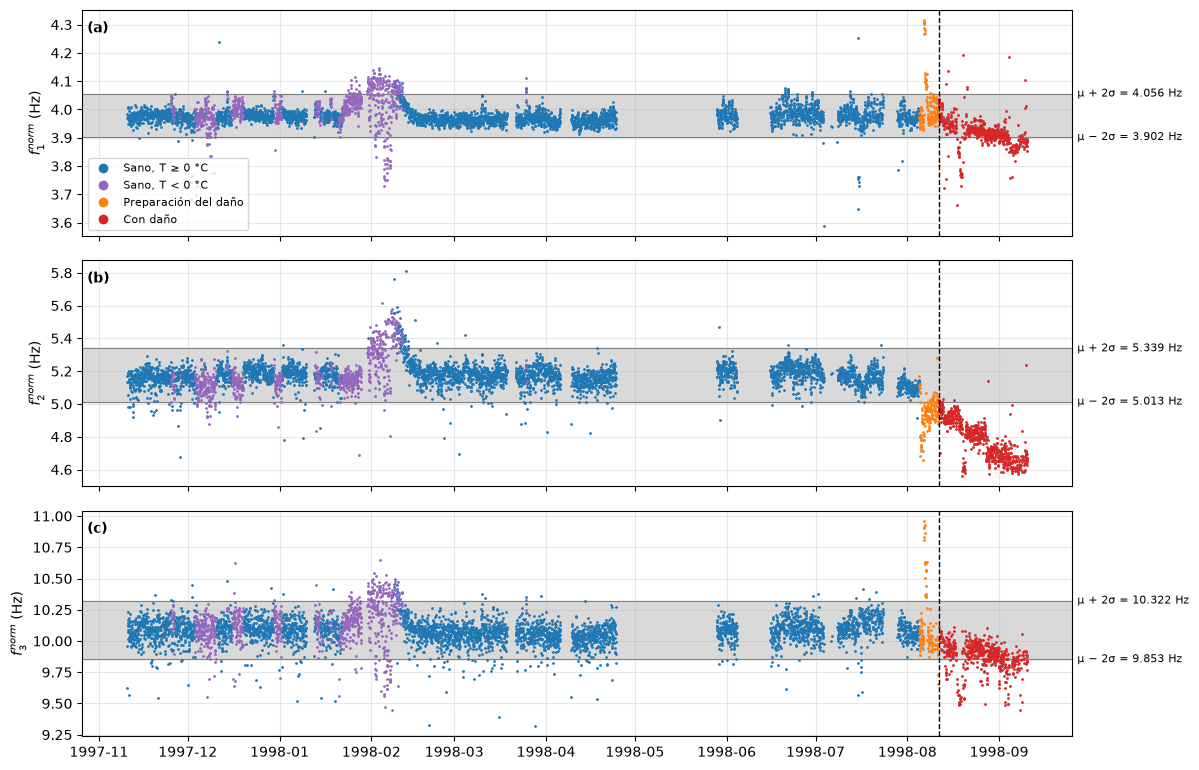

**Figura 7.** Frecuencias normalizadas a 10 °C (Ec. 3) a lo largo del monitoreo: (a) modo 1, (b) modo 2 y (c) modo 3. Morado: mediciones del puente sano con temperatura del pavimento bajo 0 °C. Franja gris: de μ − 2σ a μ + 2σ, con μ y σ la media y la desviación estándar de las frecuencias normalizadas del puente sano. La línea discontinua marca el primer descenso de la pila (11.08.1998).

In [10]:
def plot_band_series(groups, col, healthy):
    # Time series of col (e.g. "fn{m}") per mode, with the healthy band mu ± 2 sigma and its limits labelled
    fig, axes = plt.subplots(len(MODE_BANDS), 1, figsize=(12, 2.6 * len(MODE_BANDS)), sharex=True)
    for i, (ax, m) in enumerate(zip(axes, MODE_BANDS)):
        c = col.format(m=m)
        mu, sd = healthy[c].mean(), healthy[c].std()
        ax.axhspan(mu - 2 * sd, mu + 2 * sd, color="0.85", zorder=0)
        for y, name in [(mu + 2 * sd, "μ + 2σ"), (mu - 2 * sd, "μ − 2σ")]:
            ax.axhline(y, color="0.5", lw=0.8, zorder=0)
            ax.text(1.005, y, f"{name} = {y:.3f} Hz", transform=ax.get_yaxis_transform(), va="center", fontsize=8)
        for label, mask, color in groups:
            sel = modal[mask]
            ax.plot(sel["start"], sel[c], ".", ms=2, color=color, label=label)
        ax.axvline(DAMAGE_START, color="k", ls="--", lw=1)
        ax.set_ylabel(f"$f_{m}^{{norm}}$ (Hz)")
        ax.grid(alpha=0.3)
        ax.text(0.005, 0.95, f"({chr(97 + i)})", transform=ax.transAxes, va="top", fontweight="bold")
    axes[0].legend(markerscale=6, fontsize=8, loc="lower left")
    fig.tight_layout()
    return fig


groups = [("Sano, T ≥ 0 °C", (modal["period"] == "Sano") & (modal["T"] >= 0), "C0"),
          ("Sano, T < 0 °C", (modal["period"] == "Sano") & (modal["T"] < 0), "C4"),
          ("Preparación del daño", modal["period"] == "Preparación del daño", "C1"),
          ("Con daño", modal["period"] == "Con daño", "C3")]
fig = plot_band_series(groups, "fn{m}", sano)

f_num += 1
show_figure(fig, f_num, f"Frecuencias normalizadas a {T_REF:.0f} °C (Ec. 3) a lo largo del monitoreo: (a) modo 1, "
            "(b) modo 2 y (c) modo 3. Morado: mediciones del puente sano con temperatura del pavimento bajo 0 °C. "
            "Franja gris: de μ − 2σ a μ + 2σ, con μ y σ la media y la desviación estándar de las frecuencias "
            "normalizadas del puente sano. La línea discontinua marca el primer descenso de la pila (11.08.1998).")

- **Puente sano:** el 5 % de las mediciones queda fuera de la franja, como se espera con ± 2 desviaciones estándar. Se concentran en la helada de fines de enero a fines de febrero de 1998, donde el modelo no corrige bien (inercia térmica, sección 4.1).
- **Preparación del daño:** el modo 2 ya sale de la franja por abajo.
- **Con daño** (mediciones bajo la franja):
  - modo 2: el 99 %, desde la primera semana; baja por escalones hasta unos 4.65 Hz;
  - modo 1: el 30 %; sube del 3 % en la primera semana al 82 % en la última;
  - modo 3: el 32 %; cerca del 57 % en las dos últimas semanas.
- **Conclusión:** después de normalizar por temperatura, el daño se distingue con claridad en el modo 2 desde el primer descenso de la pila, y en los modos 1 y 3 recién con los daños de fines de agosto y septiembre. Para mejorar la corrección en la helada habría que agregar al modelo la temperatura de horas o días anteriores.

---
<a id="sec5"></a>
## 5. Prueba: normalización sin las mediciones bajo 0 °C

Prueba para comparar con la sección 4. Se repite la normalización **dejando fuera las mediciones del puente sano con temperatura del pavimento bajo 0 °C**: no se usan para ajustar el modelo ni aparecen en las gráficas. Las mediciones de la preparación y del daño no cambian, porque todas tienen temperaturas sobre 0 °C.

- **Modelo:** sin datos bajo 0 °C, la Ec. (2) se reduce a una recta, $\hat f_m(T) = a_m + b_m\,T$ ($c_m = 0$), ajustada por mínimos cuadrados.
- **Normalización:** la misma Ec. (3), con $T_{ref} = 10$ °C. Con la recta queda $f_m^{norm} = f_m - b_m\,(T - T_{ref})$.
- **Comparación:** la Tabla 8 pone lado a lado la pendiente, la dispersión del puente sano, los límites de la franja y la fracción de mediciones con daño bajo la franja de las secciones 4 y 5.

In [11]:
sano0 = modal[(modal["period"] == "Sano") & (modal["T"] >= 0)]   # healthy, without frost measurements

coefs0 = {}
for m in MODE_BANDS:
    d = sano0[["T", f"f{m}"]].dropna()
    coefs0[m] = np.polyfit(d["T"], d[f"f{m}"], 1)            # [b, a] of the straight line
    modal[f"fn0_{m}"] = modal[f"f{m}"] - coefs0[m][0] * (modal["T"] - T_REF)   # Eq. 3 with c = 0
    modal.loc[modal["T"] < 0, f"fn0_{m}"] = np.nan             # frost measurements left out
sano0 = modal[(modal["period"] == "Sano") & (modal["T"] >= 0)]
damaged = modal[modal["period"] == "Con daño"]

rows = []
for m in MODE_BANDS:
    for section, col, healthy, slope in [("4 (con T < 0 °C)", f"fn{m}", sano, coefs[m][1]),
                                         ("5 (sin T < 0 °C)", f"fn0_{m}", sano0, coefs0[m][0])]:
        mu, sd = healthy[col].mean(), healthy[col].std()
        dmg = damaged[col].dropna()
        rows.append({"Modo": m, "Sección": section, "n sano": healthy[col].notna().sum(),
                     "b (Hz/°C)": slope, "μ (Hz)": mu, "σ (Hz)": sd,
                     "μ − 2σ (Hz)": mu - 2 * sd, "μ + 2σ (Hz)": mu + 2 * sd,
                     "Sano fuera de la franja (%)": 100 * ((healthy[col] - mu).abs() > 2 * sd)[healthy[col].notna()].mean(),
                     "Con daño bajo la franja (%)": 100 * (dmg < mu - 2 * sd).mean()})

t_num += 1
show_table(pd.DataFrame(rows), t_num, f"Comparación de la normalización a {T_REF:.0f} °C con y sin las mediciones del "
           "puente sano bajo 0 °C. b: pendiente sobre 0 °C; μ y σ: media y desviación estándar de las frecuencias "
           "normalizadas del puente sano.", precision=4, hide_index=True)

**Tabla 8.** Comparación de la normalización a 10 °C con y sin las mediciones del puente sano bajo 0 °C. b: pendiente sobre 0 °C; μ y σ: media y desviación estándar de las frecuencias normalizadas del puente sano.

Modo,Sección,n sano,b (Hz/°C),μ (Hz),σ (Hz),μ − 2σ (Hz),μ + 2σ (Hz),Sano fuera de la franja (%),Con daño bajo la franja (%)
1,4 (con T < 0 °C),4768,-0.0047,3.9790,0.0384,3.9021,4.0558,4.9706,30.1226
1,5 (sin T < 0 °C),3972,-0.0042,3.9735,0.0281,3.9174,4.0297,3.1722,57.9685
2,4 (con T < 0 °C),4731,0.0010,5.1760,0.0813,5.0134,5.3385,5.6014,98.7915
2,5 (sin T < 0 °C),3982,0.0012,5.1738,0.0676,5.0386,5.3091,4.0934,99.6979
3,4 (con T < 0 °C),4688,-0.0096,10.0878,0.1173,9.8532,10.3225,5.9727,32.0965
3,5 (sin T < 0 °C),3913,-0.0084,10.0756,0.0981,9.8793,10.2719,4.4467,48.2375


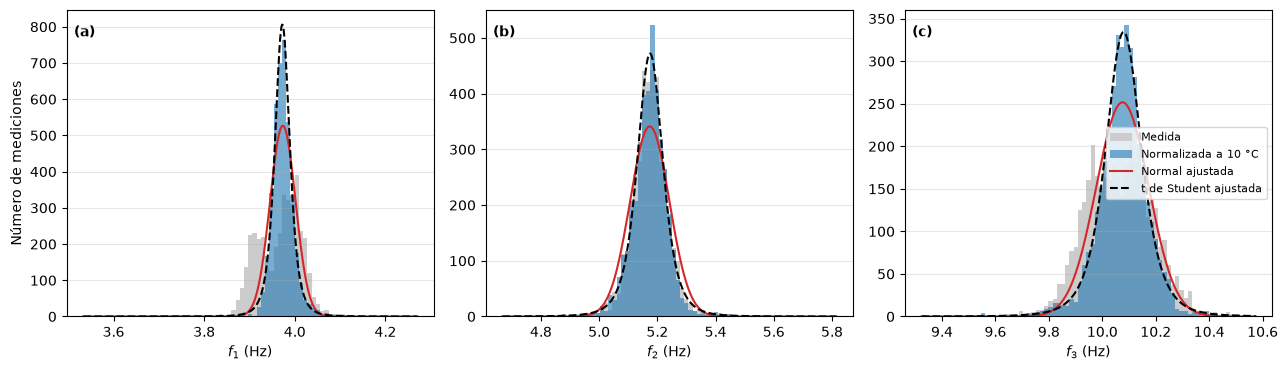

**Figura 8.** Histograma de las frecuencias del puente sano sin las mediciones bajo 0 °C (antes del 05.08.1998), medidas y normalizadas a 10 °C, con la normal (Ec. 4) y la t de Student (Ec. 5) ajustadas a las normalizadas: (a) modo 1, (b) modo 2 y (c) modo 3.

**Tabla 9.** Normal y t de Student ajustadas a las frecuencias normalizadas a 10 °C del puente sano sin las mediciones bajo 0 °C. Mismas columnas que la Tabla 7.

Modo,n,μ (Hz),σ (Hz),ν,μt (Hz),s (Hz),AIC normal,AIC t,D normal,D t,Mejor (AIC)
1,3972,3.9735,0.0281,3.5221,3.9725,0.0171,-17109.2959,-18665.6434,0.0841,0.0203,t de Student
2,3982,5.1738,0.0676,3.7162,5.1749,0.0457,-10149.1622,-11003.5607,0.0623,0.0196,t de Student
3,3913,10.0756,0.0981,3.8833,10.0796,0.0693,-7058.7127,-7656.9581,0.0675,0.0126,t de Student


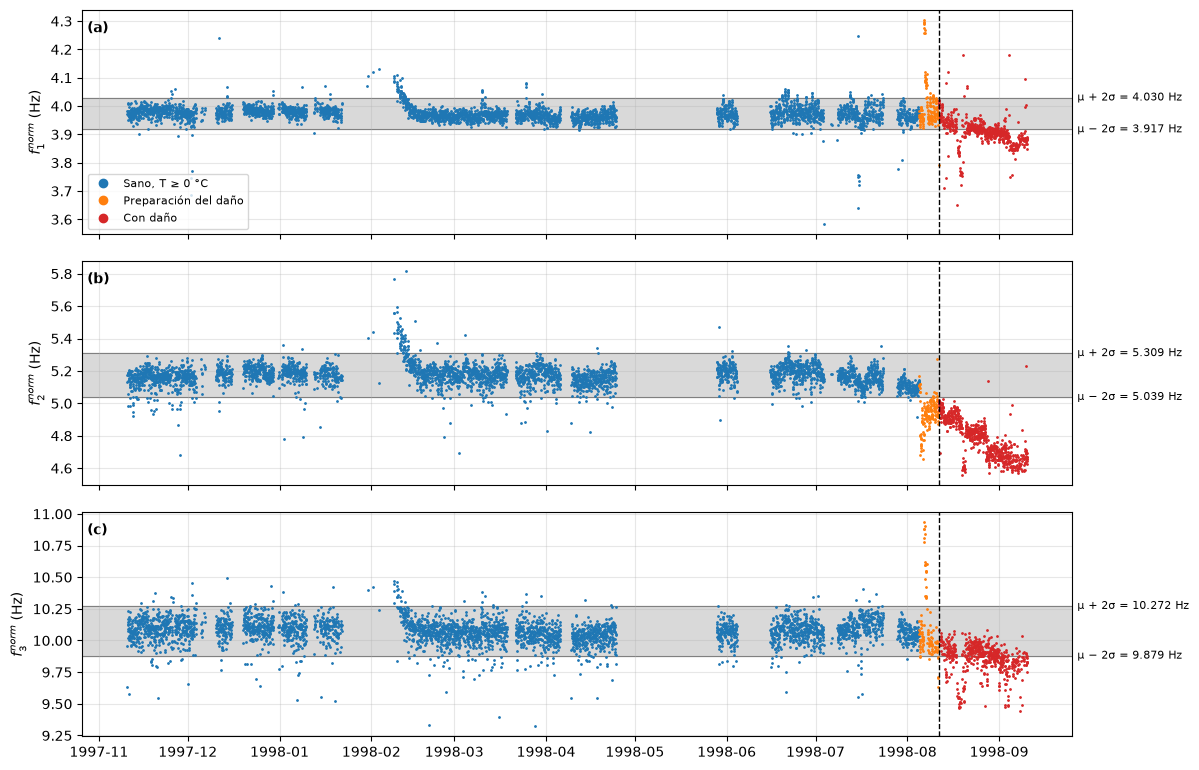

**Figura 9.** Frecuencias normalizadas a 10 °C sin las mediciones del puente sano bajo 0 °C: (a) modo 1, (b) modo 2 y (c) modo 3. Franja gris: de μ − 2σ a μ + 2σ, con μ y σ la media y la desviación estándar de las frecuencias normalizadas del puente sano sin helada. La línea discontinua marca el primer descenso de la pila (11.08.1998).

In [12]:
fits0 = plot_fit_hist(sano0, "fn0_{m}", "Histograma de las frecuencias del puente sano sin las mediciones bajo 0 °C "
                      f"(antes del 05.08.1998), medidas y normalizadas a {T_REF:.0f} °C, con la normal (Ec. 4) y la t de "
                      "Student (Ec. 5) ajustadas a las normalizadas: (a) modo 1, (b) modo 2 y (c) modo 3.")

t_num += 1
show_table(fits0, t_num, f"Normal y t de Student ajustadas a las frecuencias normalizadas a {T_REF:.0f} °C del puente sano "
           "sin las mediciones bajo 0 °C. Mismas columnas que la Tabla 7.", precision=4, hide_index=True)

groups0 = [("Sano, T ≥ 0 °C", (modal["period"] == "Sano") & (modal["T"] >= 0), "C0"),
           ("Preparación del daño", modal["period"] == "Preparación del daño", "C1"),
           ("Con daño", modal["period"] == "Con daño", "C3")]
fig = plot_band_series(groups0, "fn0_{m}", sano0)

f_num += 1
show_figure(fig, f_num, f"Frecuencias normalizadas a {T_REF:.0f} °C sin las mediciones del puente sano bajo 0 °C: "
            "(a) modo 1, (b) modo 2 y (c) modo 3. Franja gris: de μ − 2σ a μ + 2σ, con μ y σ la media y la "
            "desviación estándar de las frecuencias normalizadas del puente sano sin helada. La línea discontinua "
            "marca el primer descenso de la pila (11.08.1998).")

- **Pendiente sobre 0 °C:** casi igual con y sin helada (Tabla 8). El modelo de la sección 4 ya ajustaba bien esa parte.
- **Dispersión del puente sano:** baja de 0.038 a 0.028 Hz en el modo 1, de 0.081 a 0.068 Hz en el modo 2 y de 0.117 a 0.098 Hz en el modo 3. La franja queda más angosta.
- **Detección del daño** (mediciones con daño bajo la franja): sube del 30 % al 58 % en el modo 1 y del 32 % al 48 % en el modo 3; en el modo 2 sigue en casi el 100 %.
- **Lo que queda fuera de la franja en el puente sano:** sobre todo las horas de mediados de febrero de 1998, con el pavimento ya sobre 0 °C pero el puente todavía congelado (Figura 9). Quitar las horas bajo 0 °C no basta para eliminar el efecto de la helada; habría que quitar también los días de deshielo o modelarlos.
- **Normal o t de Student** (Figura 8 y Tabla 9): también sin la helada ajusta mejor la t en los tres modos ($D$ de 0.013 a 0.020, frente a 0.062–0.084 de la normal). Los grados de libertad suben un poco ($\nu$ = 3.5, 3.7 y 3.9): quitar la helada aligera las colas, pero siguen siendo más pesadas que las de una normal.
- **Conclusión de la prueba:** sin la helada, la distribución del puente sano es más estrecha y el daño se separa mejor en los modos 1 y 3. A cambio, el modelo solo vale para temperaturas sobre 0 °C.

---
<a id="sec6"></a>
## 6. Análisis bivariado de las frecuencias normalizadas, sobre y bajo 0 °C

Se repite el análisis bivariado de la sección 3, pero con las frecuencias normalizadas a 10 °C de la sección 4 (Ec. 3) y separando las mediciones del puente sano (antes del 05.08.1998) en dos grupos:
- **T ≥ 0 °C:** temperatura del pavimento igual o mayor que 0 °C.
- **T < 0 °C:** temperatura del pavimento bajo 0 °C.

Si la normalización quitó bien el efecto de la temperatura, la correlación que producía la temperatura (sección 3) debería desaparecer: lo que quede es la relación entre los modos que no explica la temperatura. Se usan los mismos coeficientes de Pearson (Ec. 1) y Spearman. La Tabla 10 incluye también el $\rho_s$ de las frecuencias sin normalizar (Tabla 4), para comparar.

**Contorno bivariado: modelo de Nataf.** La distribución conjunta de cada par se arma con las dos partes que ya se conocen:

- **Marginales:** cada frecuencia normalizada sigue una t de Student (Ec. 5, sección 4.2). Aquí se ajusta una t a cada frecuencia dentro de cada grupo (T ≥ 0 °C y T < 0 °C), con su propio $\nu$, centro y escala.
- **Dependencia:** la correlación entre las dos frecuencias (Tabla 10).

El **modelo de Nataf** une las dos partes. Cada frecuencia se lleva al espacio normal estándar con su propia t:

$$
z = \Phi^{-1}\!\left(F_t(f^{norm})\right)
\tag{6}
$$

- $F_t$: función de distribución acumulada de la t ajustada a esa frecuencia (la probabilidad de obtener un valor menor o igual).
- $\Phi^{-1}$: inversa de la acumulada de la normal estándar.
- En palabras: a cada frecuencia se le asigna el valor $z$ de una normal estándar que tiene la misma probabilidad acumulada. Así, cada $z$ es exactamente normal estándar, aunque la frecuencia siga una t.

En ese espacio, el par $(z_a, z_b)$ es una normal bivariada con correlación $\rho_z$ (la correlación de Pearson de los $z$ del puente sano). La región que contiene una probabilidad $p$ es una elipse:

$$
d^2 = \frac{z_a^2 - 2\rho_z z_a z_b + z_b^2}{1 - \rho_z^2} \le \chi^2_{2}(p)
\tag{7}
$$

- $d^2$: distancia de Mahalanobis al cuadrado: qué tan lejos está el punto del centro, teniendo en cuenta la correlación.
- $\chi^2_{2}(p)$: valor de la distribución chi-cuadrado con 2 grados de libertad que deja una probabilidad $p$ por debajo (5.99 para el 95 % y 9.21 para el 99 %).

El contorno se dibuja en Hz pasando la elipse de vuelta con $f^{norm} = F_t^{-1}(\Phi(z))$. Como las marginales son t y no normales, en Hz el contorno ya no es una elipse exacta: se estira hacia las colas de cada t. Un punto está fuera del contorno del 95 % si su $d^2 > 5.99$.

Para verificar el modelo, se cuenta también qué fracción del puente sano queda fuera del contorno del 95 %: si el modelo representa bien los datos, debe ser cercana al 5 %.

**Mediciones con daño.** Se agregan en los paneles con T ≥ 0 °C, coloreadas por etapa (Tabla 11). No van en los paneles con T < 0 °C porque todas se midieron con el pavimento entre 14 y 41 °C. Las fechas de las etapas salen de la Tabla 8 del Apéndice F de `C11-Appendices.pdf` y de las fechas de los informes de los ensayos PDT (`.DOC` en `pdt_01-08.zip` y `pdt_09_17.zip`), así que los límites entre etapas son aproximados (± 1 día).

**Tabla 10.** Coeficientes de correlación entre cada par de frecuencias normalizadas a 10 °C (puente sano, antes del 05.08.1998), sobre y bajo 0 °C. La última columna es el ρs de las frecuencias sin normalizar (Tabla 4).

Par,Mediciones,n,Pearson r,Spearman ρs,ρs sin normalizar
f1 – f2,T ≥ 0 °C,3934,0.36,0.35,-0.02
f1 – f2,T < 0 °C,746,0.56,0.59,0.85
f1 – f3,T ≥ 0 °C,3887,0.29,0.34,0.73
f1 – f3,T < 0 °C,772,0.73,0.75,0.91
f2 – f3,T ≥ 0 °C,3876,0.29,0.26,0.00
f2 – f3,T < 0 °C,728,0.54,0.56,0.82


**Tabla 11.** Etapas de daño usadas para colorear las mediciones con daño. Límites aproximados (± 1 día).

Etapa,Descripción,Desde,Hasta,Mediciones
Esc. 03–06,Descenso de la pila (20 a 95 mm),11.08.1998 14:00,19.08.1998 12:00,189
Esc. 07–08,"Pila levantada, inclinación de la fundación y 3.ª referencia",19.08.1998 13:00,24.08.1998 23:00,130
Esc. 09–11,Desprendimiento de hormigón y deslizamiento en un estribo,25.08.1998 00:00,30.08.1998 23:00,144
Esc. 12–14,Falla de rótulas de hormigón y de anclajes,31.08.1998 00:00,06.09.1998 23:00,154
Esc. 15–17,Rotura de cables de pretensado,07.09.1998 01:00,10.09.1998 13:00,57


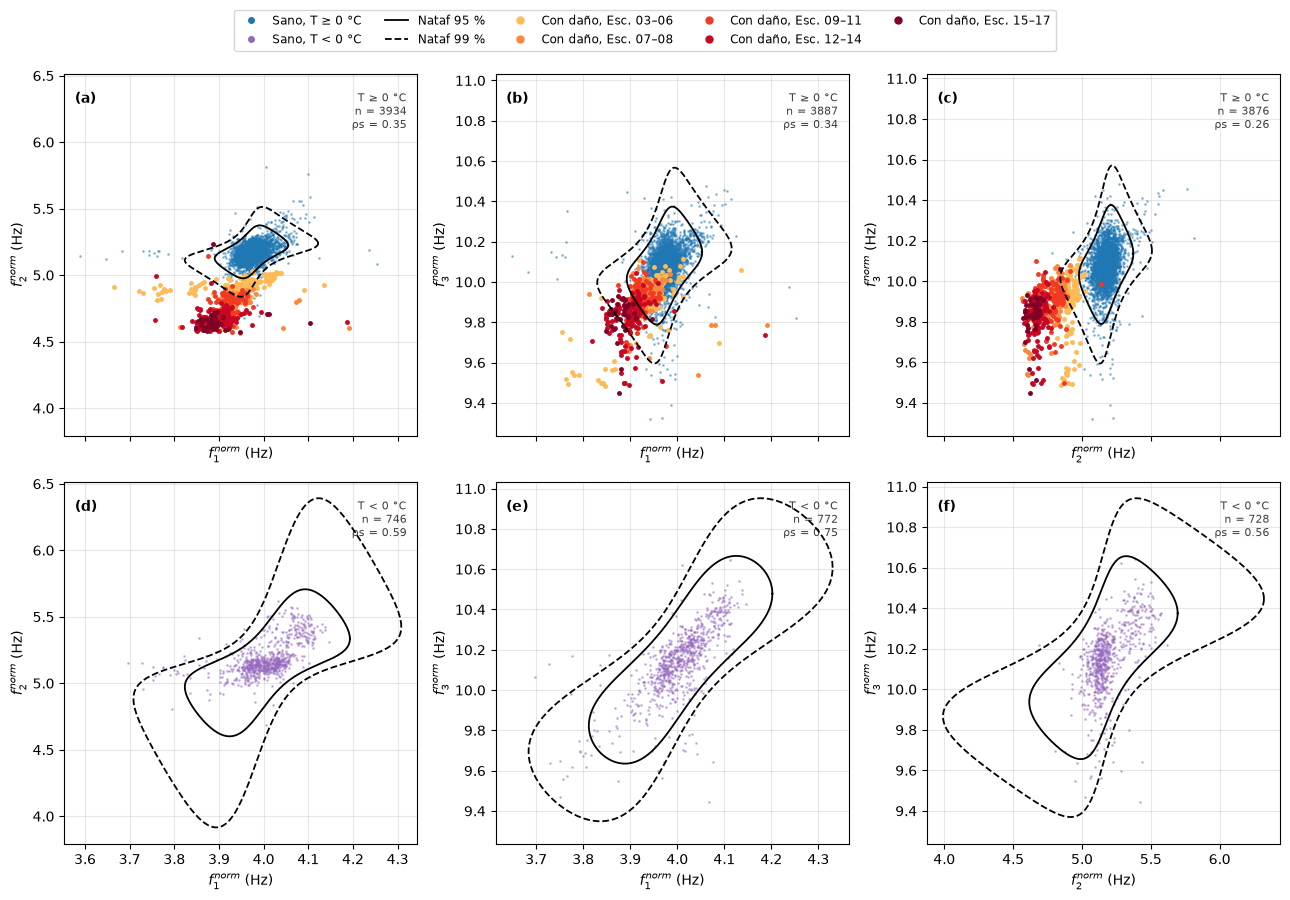

**Figura 10.** Diagramas de dispersión entre cada par de frecuencias normalizadas a 10 °C, con los contornos del modelo de Nataf del puente sano (marginales t de Student y correlación, Ec. 6 y 7) que contienen el 95 % (línea continua) y el 99 % (discontinua) de la probabilidad. Arriba, (a)–(c): puente sano con T ≥ 0 °C (antes del 05.08.1998) y mediciones con daño por etapa (Tabla 11); abajo, (d)–(f): puente sano con T < 0 °C. Columnas: $f_1$–$f_2$, $f_1$–$f_3$ y $f_2$–$f_3$; los paneles de una columna comparten los ejes.

**Tabla 12.** Modelo de Nataf de cada par y grupo: grados de libertad ν de la t de cada frecuencia (fa: la primera del par; fb: la segunda), correlación ρz en el espacio normal estándar y fracción del puente sano fuera del contorno del 95 % (debe ser cercana al 5 %).

Grupo,Par,n,ν (fa),ν (fb),ρz,Sano fuera del 95 % (%)
T ≥ 0 °C,f1 – f2,3934,3.19,3.71,0.38,5.39
T ≥ 0 °C,f1 – f3,3887,3.30,3.93,0.35,5.43
T ≥ 0 °C,f2 – f3,3876,3.77,3.89,0.28,5.11
T < 0 °C,f1 – f2,746,4.19,2.26,0.61,5.63
T < 0 °C,f1 – f3,772,3.95,4.81,0.75,5.70
T < 0 °C,f2 – f3,728,2.37,4.65,0.57,4.67


**Tabla 13.** Porcentaje de mediciones con daño fuera del contorno del 95 % del modelo de Nataf del puente sano con T ≥ 0 °C, por etapa de daño.

Par,Esc. 03–06,Esc. 07–08,Esc. 09–11,Esc. 12–14,Esc. 15–17
f1 – f2,97.1,100.0,100.0,100.0,100.0
f1 – f3,27.1,20.0,39.0,81.8,97.2
f2 – f3,95.7,100.0,99.3,100.0,100.0


In [13]:
groups_T = [("T ≥ 0 °C", sano[sano["T"] >= 0], "C0"), ("T < 0 °C", sano[sano["T"] < 0], "C4")]

rows = []
for a, b in PAIRS:
    for label, sel, _ in groups_T:
        xy = sel[[f"fn{a}", f"fn{b}"]].dropna()
        raw = sel[[f"f{a}", f"f{b}"]].dropna()
        rows.append({"Par": f"f{a} – f{b}", "Mediciones": label, "n": len(xy),
                     "Pearson r": xy.corr(method="pearson").iloc[0, 1],
                     "Spearman ρs": xy.corr(method="spearman").iloc[0, 1],
                     "ρs sin normalizar": raw.corr(method="spearman").iloc[0, 1]})

t_num += 1
show_table(pd.DataFrame(rows), t_num, f"Coeficientes de correlación entre cada par de frecuencias normalizadas a "
           f"{T_REF:.0f} °C (puente sano, antes del 05.08.1998), sobre y bajo 0 °C. La última columna es el ρs de las "
           "frecuencias sin normalizar (Tabla 4).", precision=2, hide_index=True)

# Damage stages (start of each one): Table 8 of Appendix F (C11) and the dates of the PDT reports, ± 1 day
DAMAGE_STAGES = [("Esc. 03–06", "Descenso de la pila (20 a 95 mm)", "1998-08-11 13:15"),
                 ("Esc. 07–08", "Pila levantada, inclinación de la fundación y 3.ª referencia", "1998-08-19 12:19"),
                 ("Esc. 09–11", "Desprendimiento de hormigón y deslizamiento en un estribo", "1998-08-25 00:00"),
                 ("Esc. 12–14", "Falla de rótulas de hormigón y de anclajes", "1998-08-31 00:00"),
                 ("Esc. 15–17", "Rotura de cables de pretensado", "1998-09-07 00:00")]
stage_starts = pd.to_datetime([s for _, _, s in DAMAGE_STAGES])
damaged = modal[modal["period"] == "Con daño"].copy()
damaged["stage"] = [DAMAGE_STAGES[k][0] for k in np.searchsorted(stage_starts, damaged["start"], side="right") - 1]
stage_colors = dict(zip([s for s, _, _ in DAMAGE_STAGES], plt.cm.YlOrRd(np.linspace(0.35, 1.0, len(DAMAGE_STAGES)))))

stages = damaged.groupby("stage").agg(Desde=("start", "min"), Hasta=("start", "max"), Mediciones=("code", "size"))
stages.insert(0, "Descripción", {s: d for s, d, _ in DAMAGE_STAGES})
stages[["Desde", "Hasta"]] = stages[["Desde", "Hasta"]].apply(lambda s: s.dt.strftime("%d.%m.%Y %H:%M"))
t_num += 1
show_table(stages.rename_axis("Etapa").reset_index(), t_num, "Etapas de daño usadas para colorear las mediciones con "
           "daño. Límites aproximados (± 1 día).", hide_index=True)


def fit_t(x):
    # Student t fit of a marginal (Eq. 5), same initial guess as in section 4.2
    x = np.asarray(x, float)
    return stats.t.fit(x, 5, loc=np.median(x), scale=x.std())


def to_z(x, params):
    # Eq. 6: frequency -> standard normal space through its own t marginal
    u = np.clip(stats.t.cdf(x, *params), 1e-12, 1 - 1e-12)
    return stats.norm.ppf(u)


def nataf_contour(pa, pb, rho, p, n_points=400):
    # Eq. 7: ellipse of probability p in the standard normal space, mapped back to Hz with the t marginals
    theta = np.linspace(0, 2 * np.pi, n_points)
    r = np.sqrt(stats.chi2.ppf(p, 2))
    L = np.linalg.cholesky(np.array([[1, rho], [rho, 1]]))
    z = L @ np.vstack([r * np.cos(theta), r * np.sin(theta)])
    return stats.t.ppf(stats.norm.cdf(z[0]), *pa), stats.t.ppf(stats.norm.cdf(z[1]), *pb)


def mahalanobis2(za, zb, rho):
    # Eq. 7: squared Mahalanobis distance in the standard normal space
    return (za ** 2 - 2 * rho * za * zb + zb ** 2) / (1 - rho ** 2)


D2_95 = stats.chi2.ppf(0.95, 2)
params_rows, outside = [], []
fig, axes = plt.subplots(len(groups_T), len(PAIRS), figsize=(13, 8.5), sharex="col", sharey="col")
for j, (label, sel, color) in enumerate(groups_T):
    for i, (a, b) in enumerate(PAIRS):
        ax = axes[j, i]
        xy = sel[[f"fn{a}", f"fn{b}"]].dropna()
        ax.plot(xy[f"fn{a}"], xy[f"fn{b}"], ".", ms=2, alpha=0.4, color=color)

        pa, pb = fit_t(xy[f"fn{a}"]), fit_t(xy[f"fn{b}"])
        za, zb = to_z(xy[f"fn{a}"], pa), to_z(xy[f"fn{b}"], pb)
        rho = np.corrcoef(za, zb)[0, 1]
        params_rows.append({"Grupo": label, "Par": f"f{a} – f{b}", "n": len(xy),
                            f"ν (fa)": pa[0], f"ν (fb)": pb[0], "ρz": rho,
                            "Sano fuera del 95 % (%)": 100 * np.mean(mahalanobis2(za, zb, rho) > D2_95)})
        for p, ls in [(0.99, "--"), (0.95, "-")]:
            cx, cy = nataf_contour(pa, pb, rho, p)
            ax.plot(cx, cy, color="k", ls=ls, lw=1.3, zorder=4)

        if label == "T ≥ 0 °C":
            row = {"Par": f"f{a} – f{b}"}
            for stage, _, _ in DAMAGE_STAGES:
                d = damaged.loc[damaged["stage"] == stage, [f"fn{a}", f"fn{b}"]].dropna()
                ax.plot(d[f"fn{a}"], d[f"fn{b}"], "o", ms=2.5, color=stage_colors[stage], zorder=3)
                d2 = mahalanobis2(to_z(d[f"fn{a}"], pa), to_z(d[f"fn{b}"], pb), rho)
                row[stage] = 100 * np.mean(d2 > D2_95)
            outside.append(row)

        rho_s = xy.corr(method="spearman").iloc[0, 1]
        ax.text(0.97, 0.95, f"{label}\nn = {len(xy)}\nρs = {rho_s:.2f}", transform=ax.transAxes, ha="right",
                va="top", fontsize=8, color="0.25")
        ax.set_xlabel(f"$f_{a}^{{norm}}$ (Hz)")
        ax.set_ylabel(f"$f_{b}^{{norm}}$ (Hz)")
        ax.grid(alpha=0.3)
        ax.text(0.03, 0.95, f"({chr(97 + j * len(PAIRS) + i)})", transform=ax.transAxes, va="top", fontweight="bold")
handles = ([plt.Line2D([], [], ls="", marker=".", ms=8, color=c, label=f"Sano, {l}") for l, _, c in groups_T]
           + [plt.Line2D([], [], color="k", lw=1.3, label="Nataf 95 %"),
              plt.Line2D([], [], color="k", lw=1.3, ls="--", label="Nataf 99 %")]
           + [plt.Line2D([], [], ls="", marker="o", ms=5, color=stage_colors[s], label=f"Con daño, {s}")
              for s, _, _ in DAMAGE_STAGES])
fig.legend(handles=handles, loc="upper center", ncol=5, fontsize=8.5, bbox_to_anchor=(0.5, 1.06))
fig.tight_layout()

f_num += 1
show_figure(fig, f_num, f"Diagramas de dispersión entre cada par de frecuencias normalizadas a {T_REF:.0f} °C, con los "
            "contornos del modelo de Nataf del puente sano (marginales t de Student y correlación, Ec. 6 y 7) que "
            "contienen el 95 % (línea continua) y el 99 % (discontinua) de la probabilidad. Arriba, (a)–(c): puente sano "
            "con T ≥ 0 °C (antes del 05.08.1998) y mediciones con daño por etapa (Tabla 11); abajo, (d)–(f): puente "
            "sano con T < 0 °C. Columnas: $f_1$–$f_2$, $f_1$–$f_3$ y $f_2$–$f_3$; los paneles de una columna comparten "
            "los ejes.")

t_num += 1
show_table(pd.DataFrame(params_rows), t_num, "Modelo de Nataf de cada par y grupo: grados de libertad ν de la t de cada "
           "frecuencia (fa: la primera del par; fb: la segunda), correlación ρz en el espacio normal estándar y "
           "fracción del puente sano fuera del contorno del 95 % (debe ser cercana al 5 %).", precision=2,
           hide_index=True)

t_num += 1
show_table(pd.DataFrame(outside), t_num, "Porcentaje de mediciones con daño fuera del contorno del 95 % del modelo de "
           "Nataf del puente sano con T ≥ 0 °C, por etapa de daño.", precision=1, hide_index=True)

- **T ≥ 0 °C:** después de normalizar, los tres pares quedan con una correlación positiva moderada ($\rho_s$ de 0.26 a 0.35):
  - $f_1$–$f_3$ baja de 0.73 a 0.34: la parte que producía la temperatura se fue.
  - $f_1$–$f_2$ y $f_2$–$f_3$ suben de casi 0 a 0.35 y 0.26. Sin normalizar, la temperatura movía $f_2$ en sentido contrario a $f_1$ y $f_3$ (pendiente $b$ positiva en el modo 2 y negativa en los otros, Tabla 5) y tapaba esa relación.
  - Los puntos altos de la esquina superior derecha (Figura 10a y 10c) son casi todos de los días de deshielo de febrero de 1998. Sin ellos, los coeficientes casi no cambian (0.31, 0.33 y 0.23), así que la correlación no se debe a ellos.
- **T < 0 °C:** la correlación baja respecto a las frecuencias sin normalizar (de 0.82–0.91 a 0.56–0.75), pero sigue alta, y los puntos forman una franja diagonal (Figura 10d–f). El modelo bilineal no corrige bien la helada: queda un efecto común a los tres modos (cuánto tiempo lleva helando), que los sube y baja juntos.
- **Para la distribución conjunta:** las frecuencias normalizadas no son independientes entre sí. Sobre 0 °C hay una dependencia moderada y bastante homogénea, que podría modelarse con una sola correlación (por ejemplo, una t de Student bivariada, de acuerdo con la sección 4.2). Bajo 0 °C la dependencia es más fuerte y la deja la helada no corregida; conviene modelar ese grupo por separado o mejorar antes la normalización.
- **Validez del modelo de Nataf:** fuera del contorno del 95 % queda entre el 5.1 % y el 5.4 % del puente sano con T ≥ 0 °C, y entre el 4.7 % y el 5.7 % con T < 0 °C (Tabla 12). Es lo esperado (5 %): las marginales t con la correlación $\rho_z$ representan bien la nube conjunta.
- **Forma de los contornos:** en Hz no son elipses. Son angostos cerca del centro y se estiran a lo largo de cada eje hacia las colas, porque las t tienen colas pesadas ($\nu$ entre 2.3 y 4.8): para encerrar la misma probabilidad hace falta llegar más lejos en las colas. Por la misma razón, el contorno del 99 % es mucho más grande que el del 95 %.
- **T < 0 °C:** los contornos son mucho más grandes y están inclinados en diagonal ($\rho_z$ de 0.57 a 0.75), por la helada no corregida.
- **Mediciones con daño fuera del contorno del 95 %** (Figura 10a–c y Tabla 13):
  - Pares con el modo 2 ($f_1$–$f_2$ y $f_2$–$f_3$): el 96–97 % ya en el descenso de la pila, y casi el 100 % en las etapas siguientes. Las mediciones con daño quedan debajo o a la izquierda del contorno: baja el modo 2.
  - Par $f_1$–$f_3$, sin el modo 2: la separación es gradual (27 %, 20 %, 39 %, 82 % y 97 % en las cinco etapas). Recién los daños de las etapas 12–14 y 15–17 bajan claramente los modos 1 y 3.
- **Conclusión:** con la distribución bivariada del puente sano sobre 0 °C (Nataf con marginales t), cualquier par que incluya el modo 2 separa el daño desde el primer descenso de la pila. El par $f_1$–$f_3$ lo separa solo en las etapas finales.